# Spatial transcriptomics: gene expression and tissue organization in mouse liver

Spatial transcriptomics measures gene expression while retaining information about where transcripts occur within a tissue. This adds an anatomical dimension that is missing from conventional single-cell or single-nucleus RNA sequencing.

There are two broad approaches to generating spatial transcriptomics data:
1. Sequencing-based methods, such as 10x Visium. RNA is captured at positions on a tissue slide, sequenced and assigned back to those positions. With conventional Visium, a capture spot may include several cells.
2. Imaging-based methods, such as MERFISH. Selected RNA molecules are detected directly within the tissue using microscopy. With appropriate cell segmentation, expression can be assigned to individual cells.

The examples use published mouse-liver datasets. The experiments come from different studies and animals, so they illustrate complementary approaches to the same biology rather than matched measurements.
- Part 1 — 10x Visium: [Guilliams et al., Cell (2022)](https://doi.org/10.1016/j.cell.2021.12.018), [GSE192741](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE192741), sample [GSM5764417](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM5764417).
- Part 2 — [MERFISH: Liu et al., Life Science Alliance (2022)](https://doi.org/10.26508/lsa.202201701), [public annotated mouse-liver .h5ad dataset](https://figshare.com/articles/dataset/SingleCellData_annotated_/19310672).
- Part 3 - Resolve Molecular Cartography: [Bravo González-Blas et al., Nature Cell Biology (2024)](https://doi.org/10.1038/s41556-023-01316-4), Resolve_Liver.loom under Spatial in [SCope](https://scope.aertslab.org/#/Bravo_et_al_Liver).

**Case study: How do spatially resolved transcripts reveal the organization of healthy mouse liver?**

**Research questions**

1. How does spatial resolution differ between capture-spot sequencing and imaging-based transcriptomics?
2. Which liver genes vary along the portal-to-central axis, and how can we quantify their spatial organization?
3. How do QC, segmentation and clustering choices influence the biological interpretation of spatial data?

**How to use this notebook.** Work through Parts 1–3 in order. Each part has numbered steps, explanations and questions; the exercises at the end let you test alternative settings. Files are downloaded automatically where possible, except the Resolve `.loom` file, which you must obtain from SCope. You can run the notebook in a Python Jupyter kernel with the required libraries. Large downloads and spatial permutation tests may take some time.

**To get reproducible results:** after editing code, restart the kernel and choose **Run All**. The saved example figures are illustrative; interpret the values printed by your own run.

## Overview of the analysis workflow

In this tutorial, we will analyze published spatial transcriptomics data using [Scanpy](https://scanpy.readthedocs.io/en/stable/), a Python toolkit for single-cell analysis, and [Squidpy](https://squidpy.readthedocs.io/en/stable/), which adds tools for spatial data. Starting from a processed gene-expression count matrix and spatial coordinates, we will work through the main stages of the analysis:
1. **Load and explore the data.** Examine the expression matrix, spatial coordinates, tissue image and metadata stored in an AnnData object.
2. **Quality control.** Examine detected genes, total transcript counts and mitochondrial RNA fraction across spatial locations.
3. **Preprocess the expression matrix.** Normalize for sequencing depth, log-transform counts and identify highly variable genes.
4. **Explore spatial heterogeneity.** Apply principal component analysis (PCA), construct a nearest-neighbor graph, visualize expression patterns using UMAP and identify expression-defined domains with Leiden clustering.
5. **Identify spatial expression patterns.** Map known liver markers onto the tissue and identify spatially variable genes using spatial autocorrelation.
6. **Investigate liver zonation and tissue organization.** Examine zonation-associated genes, compare with a published single-nucleus reference where available and assess spatial neighborhood enrichment.

The analysis follows the general workflow introduced in the [Scanpy clustering tutorial](https://scanpy.readthedocs.io/en/stable/tutorials/basics/clustering.html), with additional methods from the [Squidpy documentation](https://squidpy.readthedocs.io/en/stable/). Code cells are followed by interpretations or clearly marked result placeholders.

### Finding a new spatial transcriptomics dataset

For a project using spatial transcriptomics, a good starting point is a publication that analyzes spatial data. The paper's Data availability section generally specifies where the authors deposited their data, for example in the Gene Expression Omnibus (GEO) or another public repository. Published datasets often include processed expression matrices, coordinates and imaging data, although the exact files depend on the technology.

Additional resources for discovering spatial transcriptomics datasets and related publications include:
- [STOmics DB](https://db.cngb.org/stomics/)
- [SpatialDB](http://www.spatialomics.org/SpatialDB/)
- [Aquila](https://aquila.cheunglab.org/view)
- [Community-curated collection of spatial transcriptomics studies](https://docs.google.com/spreadsheets/d/1sJDb9B7AtYmfKv4-m8XR7uc3XXw_k4kGSout8cqZ8bY/edit?usp=sharing)
Before downloading, check the organism, tissue, spatial technology, sample type and available processed files. These details determine which analyses are possible.

For further guidance on spatial transcriptomics analysis, see:
- Single-cell best practices: https://www.sc-best-practices.org/spatial/introduction.html

# Part 1: Sequencing-based spatial transcriptomics (10x Visium)

## Biological background — liver tissue organization

The liver contains repeated anatomical units called lobules. Blood enters near the portal tract, flows through small vessels called sinusoids, and drains toward a central vein. Cells at different locations are exposed to different oxygen, nutrient and signaling environments.

Hepatocytes are the main metabolic cells of the liver. However, hepatocytes are not functionally identical. Their transcriptional programs change gradually along the portal-to-central axis, a phenomenon called liver zonation. For example, Glul and Cyp2e1 are associated with pericentral metabolism, whereas Cps1 and Sds are associated with periportal metabolism. These are biological expectations rather than results from this Visium sample.

Other liver populations include endothelial cells lining blood vessels, Kupffer cells (resident macrophages), hepatic stellate cells, biliary epithelial cells and immune cells. Their distribution also contributes to tissue organization.

### Biological question

How are cell-type-associated expression patterns and hepatocyte metabolic zonation organized across healthy liver tissue?

Visium allows expression to be placed back onto a tissue image. We will assess the locations of known liver markers, the emergence of expression-defined spatial domains, and the organization of zonation-associated genes. Because a Visium spot can capture multiple cells, spot-level expression is not equivalent to a single-cell measurement.

## Understanding AnnData (our data container)

An [AnnData](https://anndata.readthedocs.io/en/stable/) object stores a matrix of measurements and extra information about rows and columns. Its parts are:
- **adata.X:** Expression matrix, spots x genes
- **adata.obs:** Information about each spot, such as QC metrics
- **adata.var:** Information about each gene
- **adata.obsm["spatial"]:** Each spot's X and Y coordinates
- **adata.uns["spatial"]:** Histology image and alignment information
- **adata.layers:** Alternative versions of the expression matrix, eg.raw counts

In conventional scRNA-seq or snRNA-seq, adata.obs describes cells or nuclei. Here it describes spots, which may contain multiple cell types.

## The Visium mouse liver dataset

In this tutorial, we will analyze a published 10x Visium dataset from the healthy mouse liver, generated by Guilliams et al. (2022).

The dataset is publicly available through the Gene Expression Omnibus [(GSE192741)](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE192741). We will analyze sample [GSM5764417](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM5764417&utm_source=chatgpt.com). The public files provide a gene-expression count matrix, a histology image, spatial coordinates and image alignment information. These are the measurements used throughout the Visium analysis. Each row in the expression matrix represents a capture spot, not an individual liver cell.

Reference: [Guilliams et al., Cell (2022)](https://www.cell.com/cell/fulltext/S0092-8674(21)01481-1?_returnURL=https%3A%2F%2Flinkinghub.elsevier.com%2Fretrieve%2Fpii%2FS0092867421014811%3Fshowall%3Dtrue)

## Visium workflow

### Selecting the kernel and installing the Python environment

**Important:** The regulatory_genomics environment will be used throughout the entire practical, including Visium, MERFISH, image segmentation (watershed), and Resolve Molecular Cartography. All required packages are installed together, so you only need to create the environment once and use the same Jupyter kernel for every section.

**Note:** As in the other course practicals, we will use a dedicated **Conda/Mamba environment**. This keeps the packages required for this notebook separate from other Python projects and ensures that the notebook uses the correct versions of Scanpy, Squidpy and the image-analysis libraries.

All necessary packages can be installed together in one environment, which we will call `regulatory_genomics`. In a **terminal** connected to the same computer or VSC cluster where you run Jupyter (not in a Python notebook cell), run:

```bash
mamba create -n regulatory_genomics -c conda-forge python=3.11 scanpy "squidpy>=1.8,<1.9" anndata numpy scipy "pandas>=2.2,<3" matplotlib "scikit-image>=0.26,<0.27" h5py python-igraph leidenalg ipykernel ipywidgets
```

The version ranges help keep the environment compatible with the analysis below. `ipywidgets` provides Jupyter progress bars and avoids the optional `IProgress not found` warning. If `mamba` is unavailable, use `conda create` in the same command instead. Environment creation may take several minutes. If you already created `regulatory_genomics` earlier, **do not recreate it**; simply activate it below.

Next, activate the environment and register it as a **Jupyter kernel**. Run these commands in the terminal:

```bash
conda activate regulatory_genomics
python -m ipykernel install --user --name regulatory_genomics --display-name "Python (regulatory_genomics)"
jupyter kernelspec list
```

`ipykernel` allows Jupyter to execute the notebook using the Python interpreter and installed packages from this environment. The `--display-name` is the name shown in Jupyter's kernel menu.

Now open (or restart) Jupyter / VS Code and select **Python (regulatory_genomics)** as the notebook kernel. In VS Code, use **Select Kernel** in the top-right corner of the notebook; in classic Jupyter, use **Kernel → Change Kernel**.

If you already have a working `regulatory_genomics` kernel, you can keep using it. Do not create a new environment every time you open the notebook.

You can check the selected kernel by running this short **Python code cell** after setup:

```python
import sys
print(sys.executable)
```

The printed path should point to the Python interpreter inside your `regulatory_genomics` environment.

Installation references: [Scanpy](https://scanpy.readthedocs.io/en/stable/installation.html), [Squidpy](https://squidpy.readthedocs.io/en/latest/installation.html), and [IPython kernel registration](https://ipython.readthedocs.io/en/stable/install/kernel_install.html).

### Step 0: Set up working directory and reproducibility

All downloaded files and results are stored in folders under `PROJECT`. By default, `PROJECT` is the current working directory, so no personal cluster path is needed. In VS Code/Jupyter, check the printed directory: if the working directory is different from your notebook folder, change **only** `PROJECT` in the next cell to your own writable course folder. Downloaded files are reused on subsequent runs.

In [94]:
from pathlib import Path
import gzip
import shutil
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import squidpy as sq

# No personal username or cluster path is needed. Jupyter usually starts in
# the notebook folder; if not, set PROJECT to your own writable course folder.
PROJECT = Path.cwd().resolve()
DATA = PROJECT / 'data' / 'visium_liver_JBO004'
RESULTS = PROJECT / 'results' / 'spatial_liver'
SPATIAL = DATA / 'spatial'
for folder in (DATA, SPATIAL, RESULTS):
    folder.mkdir(parents=True, exist_ok=True)
sc.settings.set_figure_params(dpi=90, facecolor='white')
print('Working directory:', Path.cwd())
print('Course data/results directory:', PROJECT)
print('If this is not your course folder, edit PROJECT above before downloading data.')

Working directory: /lustre1/project/stg_00002/lcb/gmoro/regulatory_genomics_course
Course data/results directory: /lustre1/project/stg_00002/lcb/gmoro/regulatory_genomics_course
If this is not your course folder, edit PROJECT above before downloading data.


### Step 1: Download the Visium files

A Visium experiment includes a gene-count matrix, a tissue image, spot coordinates and information that aligns spots to the image. GEO stores these files separately. The code below downloads them into the folder layout understood by Squidpy.

Each download is checked for a nonempty result before the file is put in place. If the download fails, run the cell again.

In [95]:
BASE_URL = 'https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM5764nnn/GSM5764417/suppl/'
files = {
    'GSM5764417_filtered_feature_bc_matrix_JBO004.h5': DATA / 'filtered_feature_bc_matrix.h5',
    'GSM5764417_scalefactors_json_JBO004.json.gz': SPATIAL / 'scalefactors_json.json',
    'GSM5764417_tissue_hires_image_JBO004.png.gz': SPATIAL / 'tissue_hires_image.png',
    'GSM5764417_tissue_lowres_image_JBO004.png.gz': SPATIAL / 'tissue_lowres_image.png',
    'GSM5764417_tissue_positions_list_JBO004.csv.gz': SPATIAL / 'tissue_positions_list.csv',
}
for remote_name, destination in files.items():
    if destination.exists() and destination.stat().st_size > 0:
        print('Already present:', destination.name)
        continue
    temporary = destination.with_name(destination.name + '.part')
    with urlopen(BASE_URL + remote_name, timeout=90) as response:
        if remote_name.endswith('.gz'):
            with gzip.GzipFile(fileobj=response) as uncompressed, open(temporary, 'wb') as out:
                shutil.copyfileobj(uncompressed, out)
        else:
            with open(temporary, 'wb') as out:
                shutil.copyfileobj(response, out)
    if temporary.stat().st_size == 0:
        raise RuntimeError('Empty download: ' + remote_name)
    temporary.replace(destination)
    print('Downloaded:', destination.name, f'({destination.stat().st_size:,} bytes)')

Already present: filtered_feature_bc_matrix.h5
Already present: scalefactors_json.json
Already present: tissue_hires_image.png
Already present: tissue_lowres_image.png
Already present: tissue_positions_list.csv


### Step 2: Load and inspect the data

The following function reads both the gene-count matrix and the spatial information. Remember: rows are spots, columns are genes.

In [96]:
adata = sq.read.visium(DATA, counts_file='filtered_feature_bc_matrix.h5', library_id='JBO004')
adata.var_names_make_unique()
print(adata)
display(adata.obs.head())
display(adata.var.head())
print('Spatial coordinates shape:', adata.obsm['spatial'].shape)

AnnData object with n_obs × n_vars = 2286 × 31053
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'


/data/leuven/392/vsc39200/conda_envs/regulatory_genomics/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data/leuven/392/vsc39200/conda_envs/regulatory_genomics/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


,in_tissue,array_row,array_col
AAACAAGTATCTCCCA-1,1,50,102
AAACAGCTTTCAGAAG-1,1,43,9
AAACAGTGTTCCTGGG-1,1,73,43
AAACATTTCCCGGATT-1,1,61,97
AAACCCGAACGAAATC-1,1,45,115


,gene_ids,feature_types,genome
Xkr4,ENSMUSG00000051951,Gene Expression,mm10
Gm1992,ENSMUSG00000089699,Gene Expression,mm10
Gm37381,ENSMUSG00000102343,Gene Expression,mm10
Rp1,ENSMUSG00000025900,Gene Expression,mm10
Sox17,ENSMUSG00000025902,Gene Expression,mm10


Spatial coordinates shape: (2286, 2)


The loaded Visium object contains 2,286 capture spots and 31,053 genes. Its obs table describes the spots, var the genes, and obsm['spatial'] the spot coordinates. Importantly, these 2,286 observations are not 2,286 individual cells: each Visium spot may contain RNA from several neighboring cells.

### Step 3: See the tissue and capture spots

Squidpy plots colored circles at the measured spot coordinates on top of the H&E image.

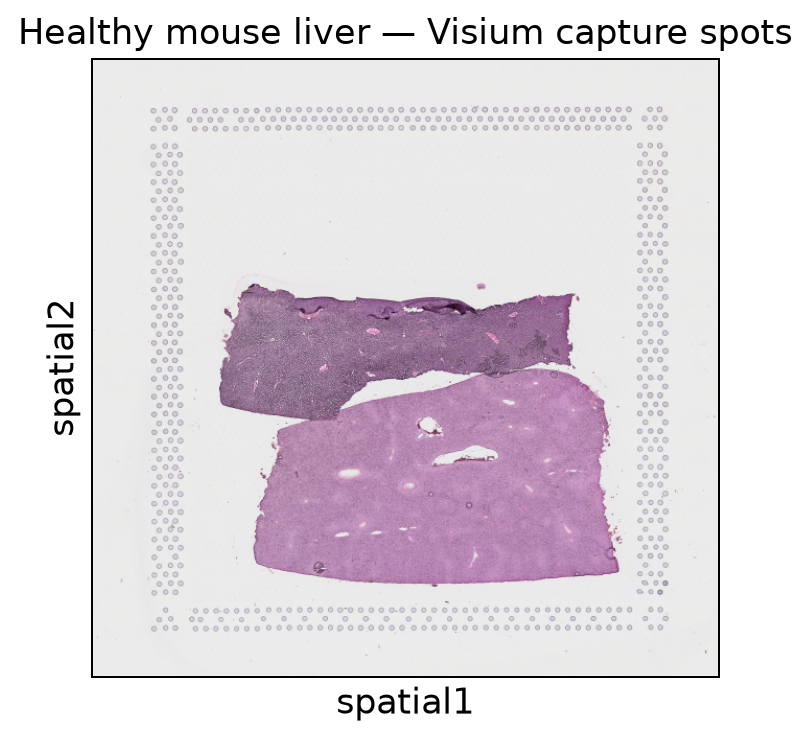

In [97]:
sq.pl.spatial_scatter(adata, img_res_key='lowres', title='Healthy mouse liver — Visium capture spots')

The H&E image shows tissue morphology beneath the Visium capture grid. Every circle is one of the 2,286 measured spots. Comparing spots with tissue landmarks helps distinguish spatial gene-expression patterns from differences in tissue coverage; the background image is not itself a gene-expression measurement.

### Step 4: Quality control (QC)

Some spots capture much more RNA than others. We first calculate:
- Total counts: number of detected transcript molecules/UMIs per spot.
- Detected genes: number of genes with at least one count per spot.
- Mitochondrial fraction: fraction of counts assigned to mitochondrial genes.
Differences can reflect tissue biology, histological features, or technical issues. Avoid copying thresholds blindly from snRNA-seq: here each observation is a spot.

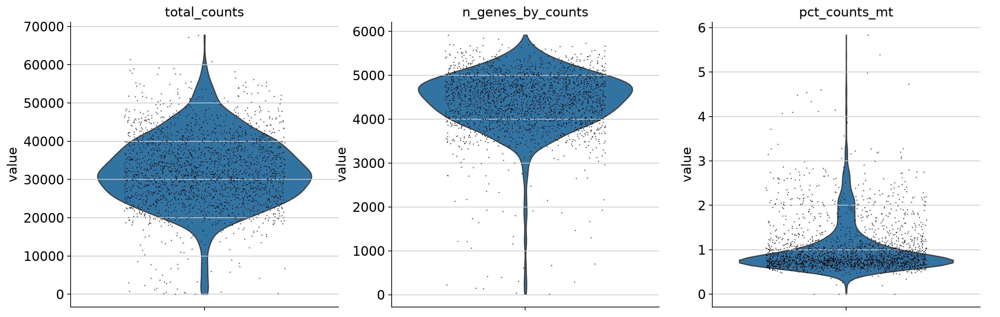

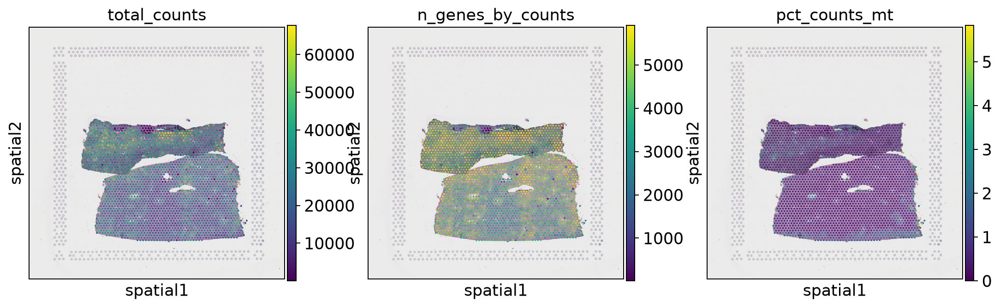

In [98]:
adata.var['mt'] = adata.var_names.str.lower().str.startswith('mt-')
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], inplace=True, percent_top=None)
sc.pl.violin(adata, ['total_counts', 'n_genes_by_counts', 'pct_counts_mt'], jitter=0.3, multi_panel=True)
sq.pl.spatial_scatter(adata, color=['total_counts', 'n_genes_by_counts', 'pct_counts_mt'], img_res_key='lowres', cmap='viridis')

The violin and tissue plots show how RNA depth, numbers of detected genes and mitochondrial fractions differ among the 2,286 spots. Since a spot can contain multiple cells, these distributions need not resemble single-cell RNA-seq QC. The following filtering step provides a direct check of whether the chosen thresholds are overly restrictive.

### Step 5: Filter low-quality spots

Quality control normally includes filtering observations that have very few detected genes or an unusually high fraction of mitochondrial counts. Unlike nuclei or whole cells, however, Visium spots can differ because of real variations in tissue composition. Filtering should therefore be conservative and informed by the plots above.

The thresholds below are illustrative starting values, not universally appropriate cutoffs. They can be adjusted once the distributions have been inspected.

In [99]:
MIN_GENES_PER_SPOT = 100
MAX_MT_PERCENT = 25.0
spots_before = adata.n_obs
keep = ((adata.obs['n_genes_by_counts'] >= MIN_GENES_PER_SPOT) &
        (adata.obs['pct_counts_mt'] <= MAX_MT_PERCENT))
print(f'Retained {int(keep.sum())} / {spots_before} spots ({100*keep.mean():.1f}%).')
if int(keep.sum()) < 100:
    raise ValueError('Very few spots passed QC. Re-examine the QC plots and thresholds.')
adata = adata[keep].copy()

Retained 2284 / 2286 spots (99.9%).


With the demonstrated cutoffs of at least 100 detected genes and at most 25% mitochondrial counts, 2,284 of 2,286 spots remain (99.9%). Only two spots were removed. This is conservative filtering for this particular sample, not a general Visium QC rule.

**Question:** The cutoff removes very few Visium spots. Would that always indicate good tissue quality? Which QC metrics would you check before using the same thresholds on a different tissue?

### Step 6: Normalize and map gene expression

Raw Visium spots contain different total numbers of UMIs. We normalize each spot to a common total and apply `log1p`, which compresses large expression values. We preserve the original molecule counts in `adata.layers['counts']`.

**Safe to rerun:** the cell below creates the counts layer only if it does not exist, then always restores `adata.X` from those original counts before normalization. Rerunning the cell will not double-normalize or overwrite the count layer. If you want to change the earlier *spot QC thresholds*, restart Part 1 from the data-loading step instead.

Available genes: ['Alb', 'Clec4f', 'Pecam1', 'Krt19']


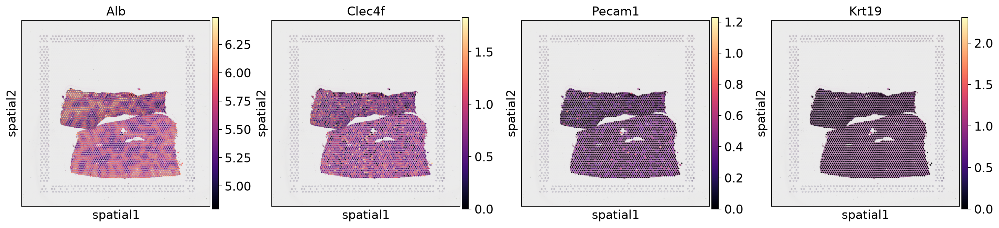

In [100]:
# Keep the original UMI counts unchanged across repeated runs of this cell.
if 'counts' not in adata.layers:
    adata.layers['counts'] = adata.X.copy()

# Restore genuine counts before filtering and normalization, even on reruns.
adata.X = adata.layers['counts'].copy()
adata.uns.pop('log1p', None)
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata.copy()

genes = [g for g in ['Alb', 'Clec4f', 'Pecam1', 'Krt19'] if g in adata.var_names]
print('Available genes:', genes)
if genes:
    sq.pl.spatial_scatter(adata, color=genes, img_res_key='lowres', cmap='magma')

All four requested genes—Alb, Clec4f, Pecam1 and Krt19—were present and plotted on the tissue. They give complementary views of hepatocyte-enriched, Kupffer-cell, endothelial and biliary signals, respectively. A bright Visium spot is not necessarily a pure population: nearby cell types contribute to the same capture spot.

### Step 7: Explore transcriptionally similar spots

The expression matrix contains thousands of genes per spot. Highly variable genes (HVGs) identify genes that differ more strongly across spots. Principal component analysis (PCA) summarizes patterns across these genes in a smaller set of dimensions. A nearest-neighbor graph then connects spots with similar expression profiles. UMAP visualizes this graph in two dimensions, while Leiden clustering groups its connected observations.

UMAP places spots near one another based on similar expression, not physical proximity. We therefore compare the UMAP clusters with their actual positions in the tissue.

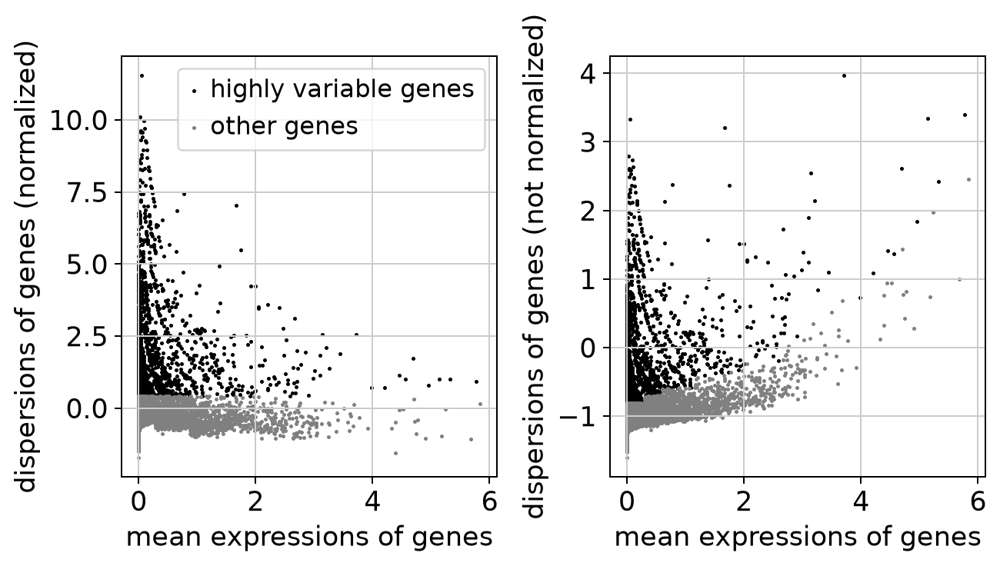

/data/leuven/392/vsc39200/conda_envs/regulatory_genomics/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


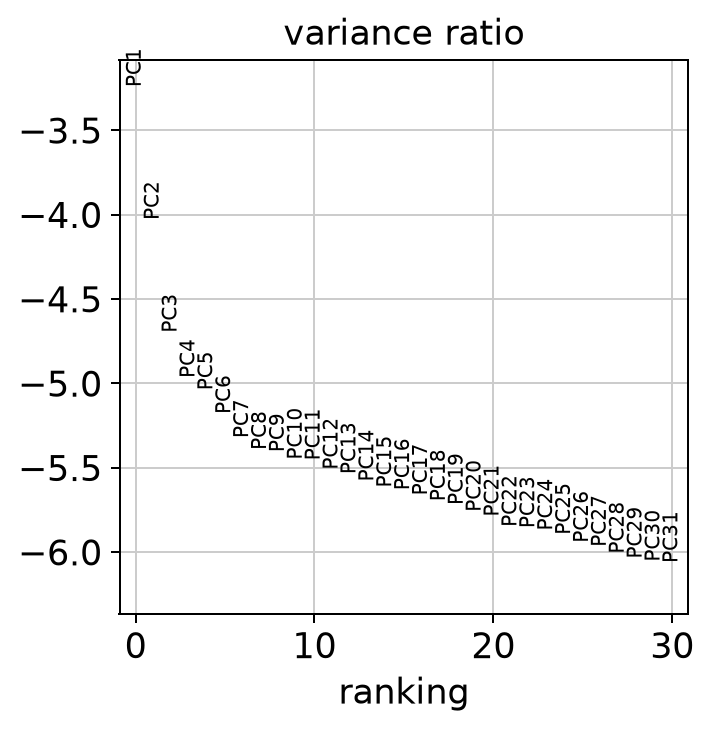

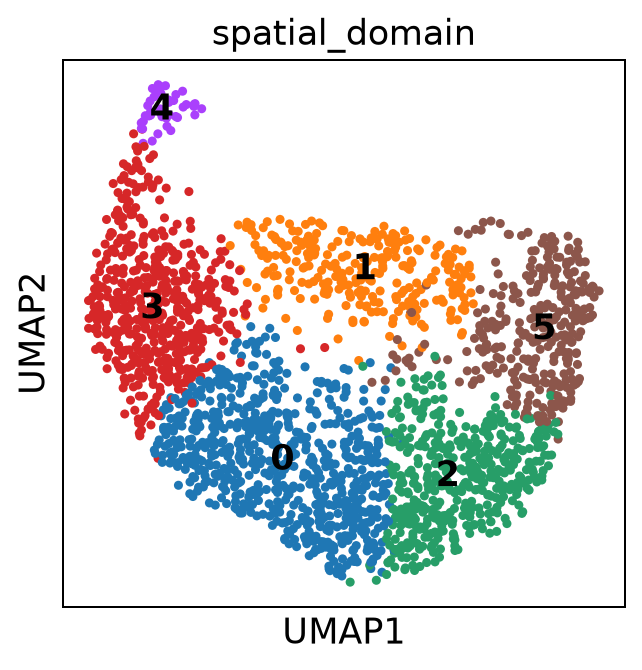

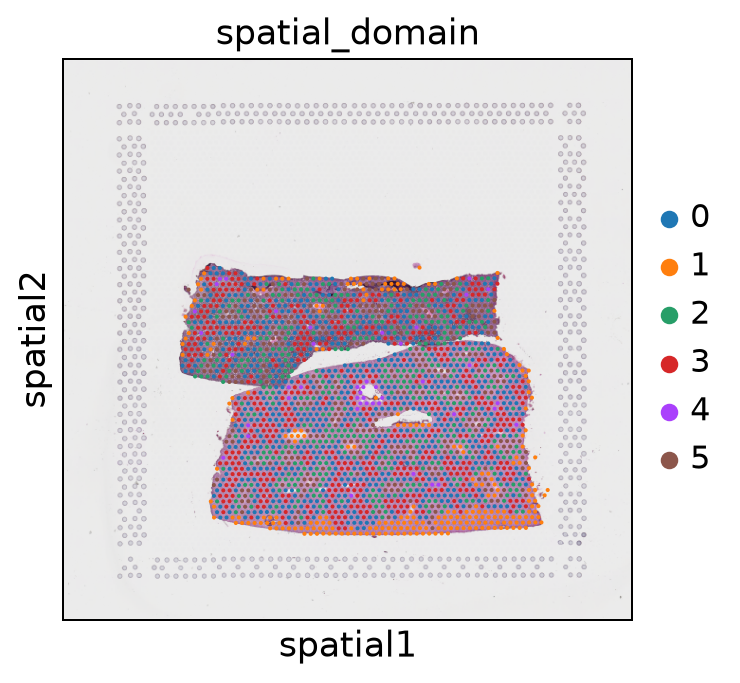

In [101]:
sc.pp.highly_variable_genes(adata, flavor='seurat', n_top_genes=min(2000, adata.n_vars))
sc.pl.highly_variable_genes(adata)
adata_hvg = adata[:, adata.var['highly_variable']].copy()
sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg)
sc.pl.pca_variance_ratio(adata_hvg, log=True)
sc.pp.neighbors(adata_hvg, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_hvg, random_state=42)
sc.tl.leiden(adata_hvg, resolution=0.4, key_added='spatial_domain', flavor='igraph', directed=False)
adata.obs['spatial_domain'] = adata_hvg.obs['spatial_domain'].copy()
adata.obsm['X_umap'] = adata_hvg.obsm['X_umap'].copy()
sc.pl.umap(adata, color='spatial_domain', legend_loc='on data')
sq.pl.spatial_scatter(adata, color='spatial_domain', img_res_key='lowres')

The PCA/UMAP/Leiden workflow ran successfully on the filtered 2,284 spots. The UMAP groups spots by transcriptional similarity, whereas the paired tissue plot shows where those groups physically lie. Comparing the panels is more informative than interpreting UMAP distance as an anatomical distance; Leiden group numbers are not liver cell-type labels.

### Hepatocyte zonation

The portal-to-central axis of the liver is associated with a gradual shift in hepatocyte metabolic programs. We can visualize this using Glul and Cyp2e1 (pericentral-associated) alongside Cps1 and Sds (periportal-associated). Spatial patterns may be gradual rather than separated into discrete compartments.

Zonation genes in this sample: ['Glul', 'Cyp2e1', 'Cps1', 'Sds']


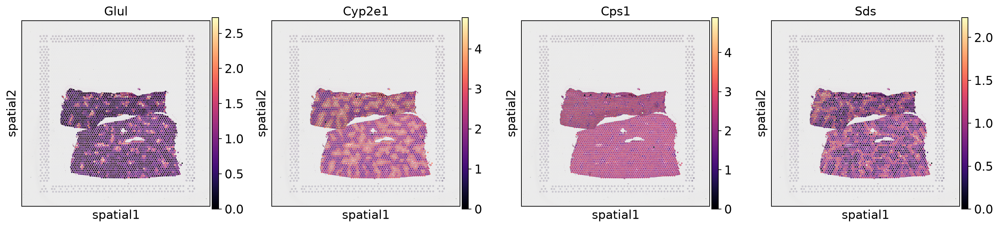

In [102]:
zonation = [g for g in ['Glul', 'Cyp2e1', 'Cps1', 'Sds'] if g in adata.var_names]
print('Zonation genes in this sample:', zonation)
if zonation:
    sq.pl.spatial_scatter(adata, color=zonation, img_res_key='lowres', cmap='magma')

The observed sample contains all four tested zonation genes: Glul, Cyp2e1, Cps1 and Sds. Glul and Cyp2e1 are consistent with pericentral-associated programs, whereas Cps1 and Sds help examine other lobular zones. The expression overlays can suggest metabolic zonation, but an individual spot cannot establish an anatomical vein identity.

### Step 8: Zoom into a candidate liver lobule

To examine lobule-scale zonation, we want a region **inside the tissue**, rather than an isolated bright *Glul* spot near a tissue edge. The code estimates how many neighboring Visium spots surround each spot and selects a high-*Glul* location among well-supported interior positions. This is a practical starting point, not an anatomical identification of a central vein or an entire lobule.

Inspect the H&E image and adjust `LOBULE_CENTER` and `LOBULE_HALF_WIDTH` if another interior region better shows the anatomy. The crop coordinate order in Squidpy is `(x_min, y_min, x_max, y_max)`.

[Squidpy spatial-plotting documentation](https://squidpy.readthedocs.io/en/stable/api/squidpy.pl.spatial_scatter.html)

Interior candidate spots: 1071 / 2284
Interior candidate center: [1119. 1441.]
Crop (x_min, y_min, x_max, y_max): (973, 1295, 1264, 1586)
Inspect tissue morphology; adjust LOBULE_CENTER and LOBULE_HALF_WIDTH if needed.


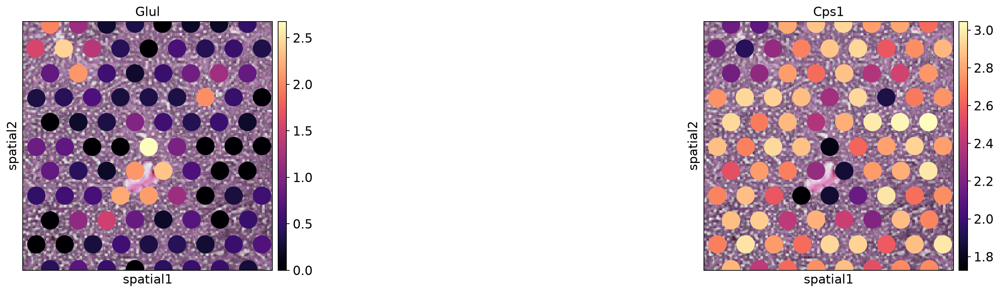

In [103]:
from scipy.spatial import cKDTree
from scipy import sparse as sparse_matrix

spot_xy = np.asarray(adata.obsm['spatial'], dtype=float)
spot_tree = cKDTree(spot_xy)
spot_pitch = np.median(spot_tree.query(spot_xy, k=2)[0][:, 1])

# Interior spots have neighbors in all directions; edge spots have fewer.
neighbor_counts = spot_tree.query_ball_point(
    spot_xy, r=4 * spot_pitch, return_length=True
)
interior_spots = neighbor_counts >= np.percentile(neighbor_counts, 75)
print(f'Interior candidate spots: {int(interior_spots.sum())} / {adata.n_obs}')

if 'Glul' in adata.var_names:
    signal = adata[:, 'Glul'].X
    glul_expression = (signal.toarray().ravel() if sparse_matrix.issparse(signal)
                       else np.asarray(signal).ravel())
    ranked_signal = np.where(interior_spots, glul_expression, -np.inf)
    LOBULE_CENTER = spot_xy[np.argmax(ranked_signal)].copy()
else:
    LOBULE_CENTER = np.median(spot_xy[interior_spots], axis=0)

# Editable region width (in full-resolution spot-coordinate units).
LOBULE_HALF_WIDTH = 4.5 * spot_pitch
lobule_crop = (
    int(LOBULE_CENTER[0] - LOBULE_HALF_WIDTH),  # x_min
    int(LOBULE_CENTER[1] - LOBULE_HALF_WIDTH),  # y_min
    int(LOBULE_CENTER[0] + LOBULE_HALF_WIDTH),  # x_max
    int(LOBULE_CENTER[1] + LOBULE_HALF_WIDTH),  # y_max
)
zoom_genes = [g for g in ('Glul', 'Cps1') if g in adata.var_names]
print('Interior candidate center:', LOBULE_CENTER.round(0))
print('Crop (x_min, y_min, x_max, y_max):', lobule_crop)
sq.pl.spatial_scatter(
    adata, color=zoom_genes or ['spatial_domain'], img_res_key='hires',
    crop_coord=lobule_crop, cmap='magma', figsize=(10, 5), ncols=2,
)
print('Inspect tissue morphology; adjust LOBULE_CENTER and LOBULE_HALF_WIDTH if needed.')

This close-up prioritizes Visium spots in an **interior tissue region** rather than the absolute *Glul* maximum, which may lie near the tissue boundary. Check the H&E image and compare *Glul* with *Cps1*. A zonation pattern suggests a portal–central gradient, but neither spot expression nor a crop alone establishes the identity of a vein or proves that a complete lobule is visible. Each circle is still a multi-cell Visium capture spot.

**Question:** How do the *Glul* and *Cps1* patterns differ in the selected region? Which histological landmark would you need to see before calling the center a central vein?

### Step 9: Identify spatially variable genes

Highly variable genes vary between observations, but do not necessarily form patterns on the tissue. Spatial analysis tests whether nearby spots have more similar expression than expected by chance. A common measure is Moran’s I. Positive values suggest spatial clustering of expression; values near zero indicate little spatial structure

INFO     Creating graph using `None` transform and `1` libraries.                                                  


100%|██████████| 100/100 [00:13<00:00,  7.22/s]


,I,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
Cyp2e1,0.544989,0.0,0.000157,0.0,0.009901,0.000151,0.0,0.0,0.031475
Rgn,0.507599,0.0,0.000157,0.0,0.009901,0.000171,0.0,0.0,0.031475
Gsta3,0.448518,0.0,0.000157,0.0,0.009901,0.000169,0.0,0.0,0.031475
Pigr,0.418843,0.0,0.000157,0.0,0.009901,0.000137,0.0,0.0,0.031475
Pck1,0.394421,0.0,0.000157,0.0,0.009901,0.000153,0.0,0.0,0.031475
Sds,0.386480,0.0,0.000157,0.0,0.009901,0.000151,0.0,0.0,0.031475
Glul,0.359783,0.0,0.000157,0.0,0.009901,0.000143,0.0,0.0,0.031475
Rps4x,0.356602,0.0,0.000157,0.0,0.009901,0.000153,0.0,0.0,0.031475
Sord,0.352932,0.0,0.000157,0.0,0.009901,0.000166,0.0,0.0,0.031475
Slc1a2,0.301394,0.0,0.000157,0.0,0.009901,0.000117,0.0,0.0,0.031475


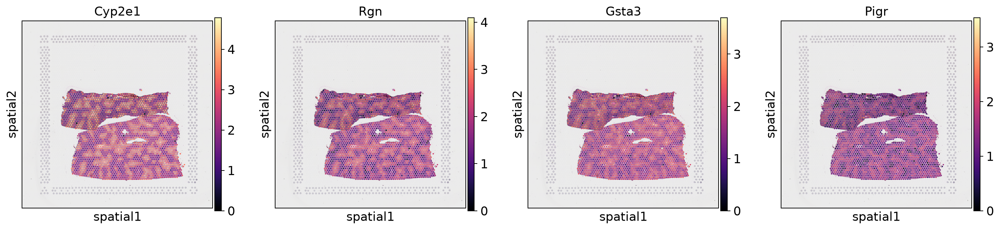

In [104]:
sq.gr.spatial_neighbors_grid(adata, n_neighs=6)
tested_genes = list(dict.fromkeys(zonation + adata.var_names[adata.var['highly_variable']].tolist()[:300]))
sq.gr.spatial_autocorr(adata, mode='moran', genes=tested_genes, n_perms=100, n_jobs=1, seed=42)
display(adata.uns['moranI'].head(12))
top_spatial_genes = [g for g in adata.uns['moranI'].head(4).index if g in adata.var_names]
if top_spatial_genes:
    sq.pl.spatial_scatter(adata, color=top_spatial_genes, img_res_key='lowres', cmap='magma')

The executed Visium Moran's I analysis identifies particularly structured genes: Cyp2e1 (I = 0.545), Rgn (0.508), Gsta3 (0.449), Pigr (0.419), Pck1 (0.394), Sds (0.386) and Glul (0.360). Positive values mean that nearby capture spots have more similar expression than expected under the chosen spatial graph. All are associations at the spot level, not direct cell-cell interactions.

### Step 10: Spatial neighborhood enrichment

We can now examine the spatial organization of our expression-defined Leiden domains using the Visium spot-neighbor graph. Neighborhood enrichment tests whether two labeled domains appear next to each other more often than expected when the domain labels are randomized. This measures spot adjacency, not direct cell–cell contact.

100%|██████████| 100/100 [00:00<00:00, 1759.21/s]


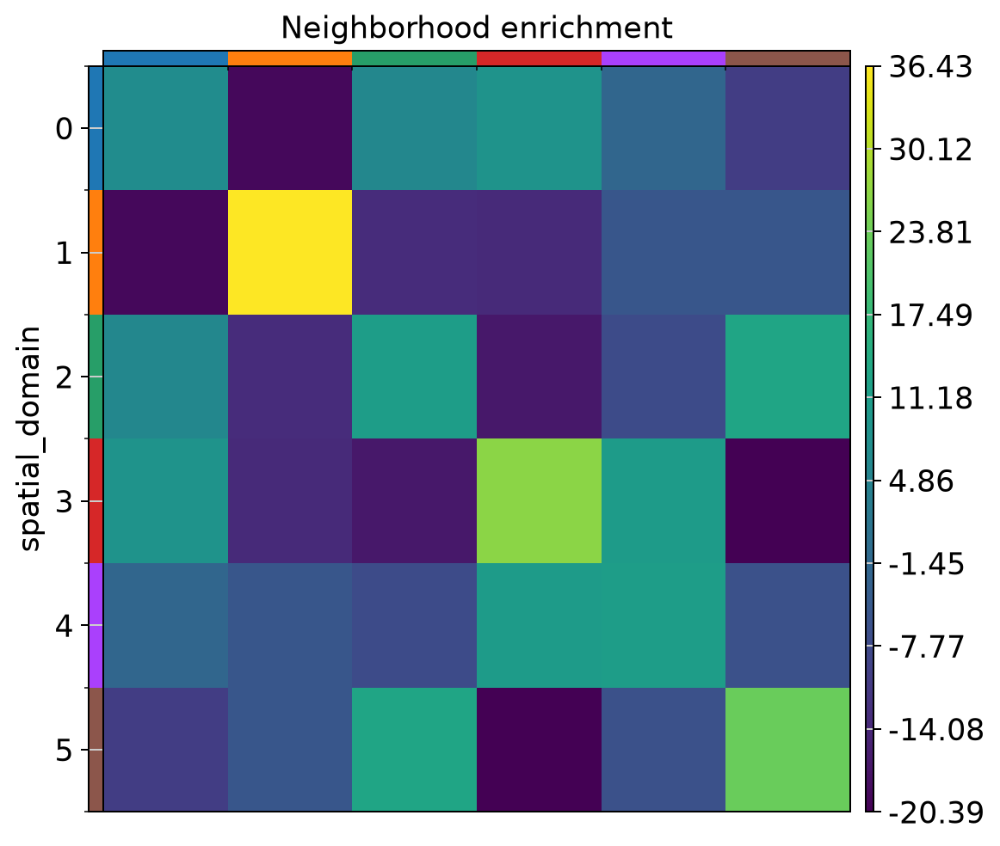

In [105]:
sq.gr.nhood_enrichment(adata, cluster_key='spatial_domain', n_perms=100, seed=42)
sq.pl.nhood_enrichment(adata, cluster_key='spatial_domain', figsize=(6, 5))

The enrichment heatmap compares adjacency between the Leiden-defined Visium spot domains after 100 label permutations. Positive values mean two domains appear next to one another more often than expected by chance; negative values imply avoidance. Because the objects are multicellular capture spots, the heatmap must not be read as a cell-contact map.

### Step 11: Save the processed Visium dataset

Save the spatial AnnData object to preserve the normalized counts, spatial coordinates, QC metrics, expression-defined domains, Moran’s I results and optional reference scores. The figures can then be recreated without repeating the preprocessing steps.

In [106]:
output = RESULTS / 'visium_mouse_liver_processed.h5ad'
adata.write_h5ad(output, compression='gzip')
print('Saved:', output)
print('File size (bytes):', output.stat().st_size)

Saved: /lustre1/project/stg_00002/lcb/gmoro/regulatory_genomics_course/results/spatial_liver/visium_mouse_liver_processed.h5ad
File size (bytes): 77066565


# Part 2: Imaging-based spatial transcriptomics (MERFISH)

## Introduction to MERFISH and the published mouse-liver dataset

MERFISH detects RNA molecules in intact tissue using fluorescence microscopy and a combinatorial probe readout. Unlike Visium, which captures RNA in fixed-size spots, MERFISH detects individual molecules, and expression values are summarized per segmented cell.

The published dataset in this section comes from [Liu et al., Life Science Alliance (2022)](https://doi.org/10.26508/lsa.202201701), Concordance of MERFISH spatial transcriptomics with bulk and single-cell RNA sequencing. The authors measured a 307-gene targeted panel in mouse liver and kidney. Their mouse-liver analysis resolved hepatocytes, endothelial populations, Kupffer cells and other cell types, as well as periportal and pericentral spatial organization.

We use the annotated, processed mouse-liver dataset, deposited by Angela Pisco:
- Figshare dataset and description: https://figshare.com/articles/dataset/SingleCellData_annotated_/19310672
- Direct download — MERFISH_liver_object.h5ad (~54 MB): https://ndownloader.figshare.com/files/36879168
- Original figure-reproduction notebooks: https://github.com/czbiohub-sf/MERFISH-mouse-comparison
- Figure 6 — cell types and spatial maps: https://doi.org/10.26508/lsa.202201701
The annotated file contains the expression matrix, cell metadata and physical cell coordinates in obsm["spatial"] (micrometres). It also stores the authors' manually assigned cell-type labels (free_annotation). No registration, institutional storage or prior notebook is require

## Biological context and analysis approach

We continue investigating liver zonation, now at single-cell resolution. We will first inspect the spatial positions and authors' annotations, then reconstruct a basic expression-based analysis using stored molecule counts. We will compare transcriptomic clusters with known cell identities, examine spatial marker-gene patterns, and quantify spatial structure with Moran's I and neighborhood enrichment.

The distinction from Visium: neighboring MERFISH cells are individually segmented, although segmentation can be imperfect; neighboring Visium spots usually contain contributions from several cells.

## MERFISH workflow

### Step 0: Download the annotated MERFISH file

We can download the .h5ad file directly from Figshare. The download is skipped if the file is already present. The file format is AnnData, which stores expression data and annotations together. The expression matrix and physical coordinates are packaged together, so we do not need to match separate CSV files manually.

In [107]:
MERFISH_DATA = PROJECT / 'data' / 'merfish_mouse_liver_Liu2022'
MERFISH_DATA.mkdir(parents=True, exist_ok=True)
MERFISH_FILE = MERFISH_DATA / 'MERFISH_liver_object.h5ad'
MERFISH_URL = 'https://ndownloader.figshare.com/files/36879168'

if not MERFISH_FILE.exists() or MERFISH_FILE.stat().st_size == 0:
    temporary = MERFISH_FILE.with_suffix('.h5ad.part')
    print('Downloading public mouse-liver MERFISH data (~54 MB)...')
    with urlopen(MERFISH_URL, timeout=180) as response, open(temporary, 'wb') as out:
        shutil.copyfileobj(response, out)
    if temporary.stat().st_size == 0:
        raise RuntimeError('The MERFISH download was empty.')
    temporary.replace(MERFISH_FILE)
print('MERFISH file:', MERFISH_FILE)
print('File size:', round(MERFISH_FILE.stat().st_size / 1e6, 1), 'MB')

MERFISH file: /lustre1/project/stg_00002/lcb/gmoro/regulatory_genomics_course/data/merfish_mouse_liver_Liu2022/MERFISH_liver_object.h5ad
File size: 53.8 MB


The publicly downloaded file is an annotated AnnData .h5ad containing gene expression, cell metadata and spatial coordinates. Unlike the Visium sample, a separate tissue image is not needed to plot the segmented-cell centroids. Importantly, the .h5ad does not include the original DAPI microscopy image; we fetch an authentic image separately below for the segmentation exercise.

### Step 1: Load and explore the AnnData object

With MERFISH, the rows of the expression matrix correspond to segmented cells, whereas in Visium they correspond to capture spots. We first examine the matrix dimensions and the names of observation-level and gene-level metadata.

Importantly, the authors' annotated .h5ad contains already processed expression values. We will explicitly restore the molecular counts stored in layers["counts"] before recalculating QC or normalization, to avoid treating scaled values as raw counts.

In [108]:
merfish_published = sc.read_h5ad(MERFISH_FILE)
merfish_published.var_names_make_unique()
print(merfish_published)
print('Cell metadata:', merfish_published.obs.columns.tolist())
print('Gene metadata:', merfish_published.var.columns.tolist())
print('Expression layers:', list(merfish_published.layers.keys()))
print('Spatial keys:', list(merfish_published.obsm.keys()))
display(merfish_published.obs.head())
assert 'spatial' in merfish_published.obsm, 'The expected spatial coordinates are missing.'
assert 'free_annotation' in merfish_published.obs, 'The published cell annotations are missing.'
assert 'counts' in merfish_published.layers, 'Expected molecule counts are missing; inspect this h5ad before preprocessing.'
print('Coordinates:', merfish_published.obsm['spatial'].shape)

merfish = merfish_published.copy()
merfish.X = merfish.layers['counts'].copy()
merfish.raw = None  # Clear any pre-existing normalized reference for this fresh analysis.
merfish.obs['free_annotation'] = merfish.obs['free_annotation'].astype('category')
print('Starting again from the stored molecule-count matrix.')

AnnData object with n_obs × n_vars = 34217 × 307
    obs: 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'min_y', 'max_x', 'max_y', 'barcodeCount', 'average_DAPI_score', 'area', 'n_counts', 'leiden', 'free_annotation'
    uns: 'free_annotation_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'
Cell metadata: ['fov', 'volume', 'center_x', 'center_y', 'min_x', 'min_y', 'max_x', 'max_y', 'barcodeCount', 'average_DAPI_score', 'area', 'n_counts', 'leiden', 'free_annotation']
Gene metadata: []
Expression layers: ['counts']
Spatial keys: ['X_pca', 'X_umap', 'spatial']


,fov,volume,center_x,center_y,min_x,min_y,max_x,max_y,barcodeCount,average_DAPI_score,area,n_counts,leiden,free_annotation
79,NaN,131801.930691,38385.087222,3830.896267,38299.391204,3755.753711,38462.262006,3893.000000,289.0,5292.381008,1581.597436,289.0,3,pericentral hepatocyte
83,NaN,108851.000059,38509.648904,3875.023162,38435.170597,3811.620121,38580.026192,3943.565070,391.0,4565.679348,1306.190752,391.0,3,pericentral hepatocyte
86,NaN,89270.962484,38290.840259,3909.486730,38228.403990,3857.574182,38350.226270,3960.977006,181.0,5144.508212,1071.234121,181.0,5,pericentral hepatocyte
90,NaN,72754.461865,38476.278879,3968.778575,38412.238598,3921.448728,38546.764135,4011.138040,210.0,3167.122601,873.039340,210.0,2,pericentral hepatocyte
91,NaN,32280.005798,38219.940797,4006.663258,38181.324071,3953.887765,38292.473600,4034.001966,108.0,2934.364650,387.353768,108.0,2,pericentral hepatocyte


Coordinates: (34217, 2)
Starting again from the stored molecule-count matrix.


The downloaded MERFISH dataset contains 34,217 segmented cells and 307 measured genes, with coordinates in obsm['spatial']. The observations include free_annotation, cell area, volume and count metadata. Since the assay measures a targeted panel, lack of expression for a gene outside these 307 targets cannot be interpreted as true absence.

### Step 2: Visualize annotated cells in the tissue

The spatial embedding represents real positions in the mouse-liver section, unlike a UMAP, whose coordinates are inferred from expression similarity. The plotted cell labels were assigned in the published study and provide an anatomical reference for our independent clustering analysis.

The authors' coordinate units are micrometres, and the x and y axes should be plotted at the same scale. We can flip the displayed y axis to match the usual orientation of microscopy images without changing stored coordinates.

Published liver cell types:


,Cells
free_annotation,
periportal hepatocyte,14083
pericentral hepatocyte,12708
Kupffer cell,2391
hepatic stellate cell,1639
periportal endothelial cell,1636
pericentral endothelial cell,1529
immune cell,171
bile duct epithelial cell,60


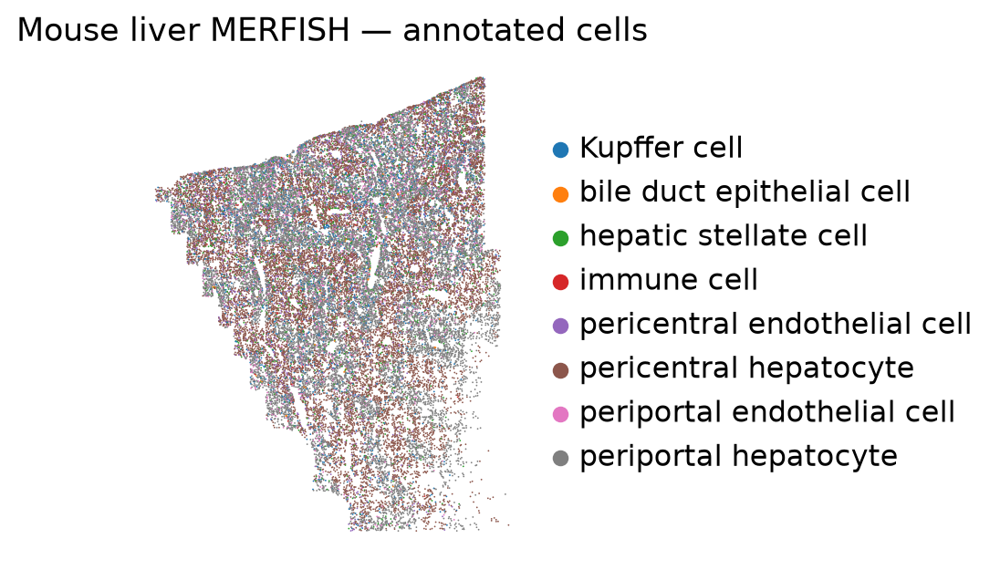

In [109]:
print('Published liver cell types:')
display(merfish.obs['free_annotation'].value_counts().to_frame('Cells'))

spatial_axes = sc.pl.embedding(
    merfish, basis='spatial', color='free_annotation',
    size=2, frameon=False, title='Mouse liver MERFISH — annotated cells',
    show=False,
)
spatial_axes.set_aspect('equal')
spatial_axes.invert_yaxis()
spatial_axes.set_xlabel('X (µm)')
spatial_axes.set_ylabel('Y (µm)')
plt.show()

The published annotations contain 14,083 periportal hepatocytes and 12,708 pericentral hepatocytes, together with 2,391 Kupffer cells, 1,639 stellate cells, 1,636 periportal endothelial cells and 1,529 pericentral endothelial cells; rarer immune and bile-duct cells are also present. Spatial plots place individual segmented cells at their measured positions, unlike the mixed-cell Visium spots.

### Step 3: Understand cell segmentation

MERFISH images contain many fluorescent spots corresponding to individual RNA molecules. To calculate expression per cell, each RNA spot must be associated with a cell. This requires segmentation, the computational process of dividing a microscopy image into regions with distinct labels.

A nuclear stain such as DAPI, Hoechst or propidium iodide reveals DNA-rich nuclei; membrane or cytoplasmic stains can help estimate whole-cell boundaries. A simple workflow starts by finding nuclei, then extending their labels into nearby space. It is important to distinguish a nuclear mask from a validated whole-cell mask.

Segmentation mistakes matter biologically. Splitting one nucleus into multiple labels can create artificial low-count cells. Merging neighboring nuclei can combine transcripts from different cells, obscuring cell-type boundaries and affecting clusters, differential expression and spatial-neighborhood analyses.

The merfish AnnData object was already segmented and annotated by the data authors. To learn the underlying image-processing steps ourselves, we will use a raw DAPI image from the same mouse-liver MERFISH study. This raw field of view is not registered here to the cells in the downloaded AnnData object, so our segmentation is a separate teaching exercise, not a reconstruction of the authors' published whole-cell assignments.

### Step 4: Segment raw MERFISH DAPI images

The authors made the original microscopy files publicly available in the [Tabula Muris Senis S3 bucket](https://registry.opendata.aws/czb-tabula-muris-senis/) and describe the raw-image access in their [GitHub repository](https://github.com/czbiohub-sf/MERFISH-mouse-comparison). A stitched liver DAPI mosaic can be several gigabytes, but a raw `.dax` stack contains separate 16-bit image planes. We retrieve one 2048 × 2048 pixel DAPI plane (8 MiB) with an HTTP byte-range request; no multi-gigabyte download is necessary. We use field of view 350, image frame 33 from a mouse-liver sample. The public [acquisition metadata](https://czb-tabula-muris-senis.s3.amazonaws.com/spatial-transcriptomics/MERFISH-data/MsLiver_Cellbound_VZG116_V1_JH_09-18-2021/dataorganization.csv) specify frames 30–36 as DAPI, and the image-stack .inf gives 2048 × 2048, 16-bit, little-endian pixels.

The code crops a 750 × 750 pixel region to make the exercise fast. Inspect this grayscale image first. Bright regions generally indicate DNA-stained nuclei, although intensity varies and some nuclei overlap. The display contrast is adjusted for visualization, but the segmentation below uses the original unscaled pixel intensities.

You can try changing the crop [650:1400, 650:1400] later to inspect a different part of the image. The quality of segmentation can change substantially between regions.

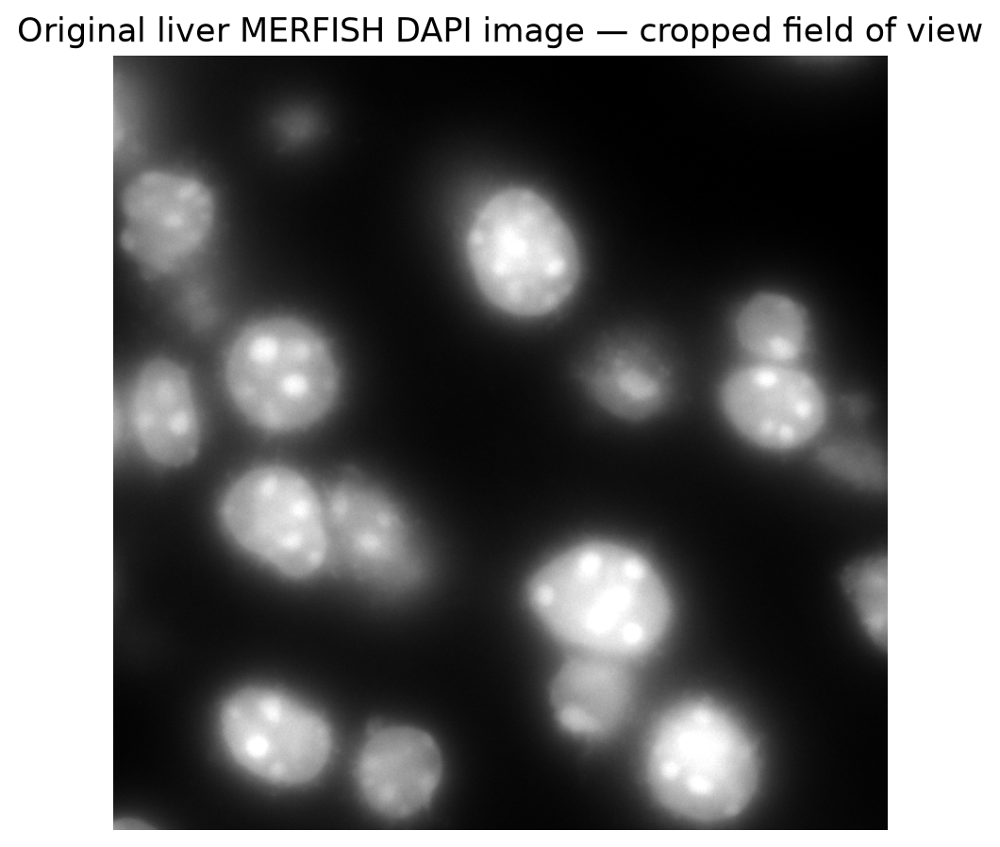

In [110]:
from urllib.request import Request, urlopen
from scipy import ndimage as ndi
import skimage as ski

# Read one original DAPI plane; the full raw stack is ~310 MB.
DAPI_URL = (
    'https://czb-tabula-muris-senis.s3.amazonaws.com/'
    'spatial-transcriptomics/MERFISH-data/'
    'MsLiver_Cellbound_VZG116_V1_JH_09-18-2021/Data/'
    'hal-config-749z7-638z7-546z7-477z9-405z7_350.dax'
)
N_PIXELS = 2048
DAPI_FRAME = 33  # metadata: DAPI frames 30–36; this is an intermediate z-plane
FRAME_BYTES = N_PIXELS * N_PIXELS * 2  # uint16 = 2 bytes per pixel
first_byte = DAPI_FRAME * FRAME_BYTES
request = Request(DAPI_URL, headers={'Range': f'bytes={first_byte}-{first_byte + FRAME_BYTES - 1}'})

with urlopen(request, timeout=120) as response:
    raw_frame = response.read()
if len(raw_frame) != FRAME_BYTES:
    raise RuntimeError('Expected one 8-MiB plane; the server did not return the requested byte range.')

dapi_full = np.frombuffer(raw_frame, dtype='<u2').reshape(N_PIXELS, N_PIXELS)
# Editable 750 x 750 pixel region with clearly visible nuclei.
dapi = dapi_full[650:1400, 650:1400].copy()
lo, hi = np.percentile(dapi, [1, 99.5])
dapi_display = ski.exposure.rescale_intensity(dapi, in_range=(lo, hi))

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(dapi_display, cmap='gray')
ax.set(title='Original liver MERFISH DAPI image — cropped field of view')
ax.axis('off')
plt.show()

#### Identify nuclear pixels using thresholding

Our first goal is to distinguish foreground (bright nuclear signal) from background (dark pixels). A binary mask contains only two values: True for pixels interpreted as nuclei and False for background.

Choosing the cutoff manually would make the result subjective. Otsu's method, implemented as ski.filters.threshold_otsu(), automatically chooses a global intensity threshold that best separates two intensity classes. We label pixels brighter than that threshold as nuclear foreground.

This is a useful starting point, not a perfect cell detector: unusually dim nuclei may be missed, and adjacent bright nuclei may form a single connected region. Plot the binary mask next to the raw DAPI crop before proceeding.

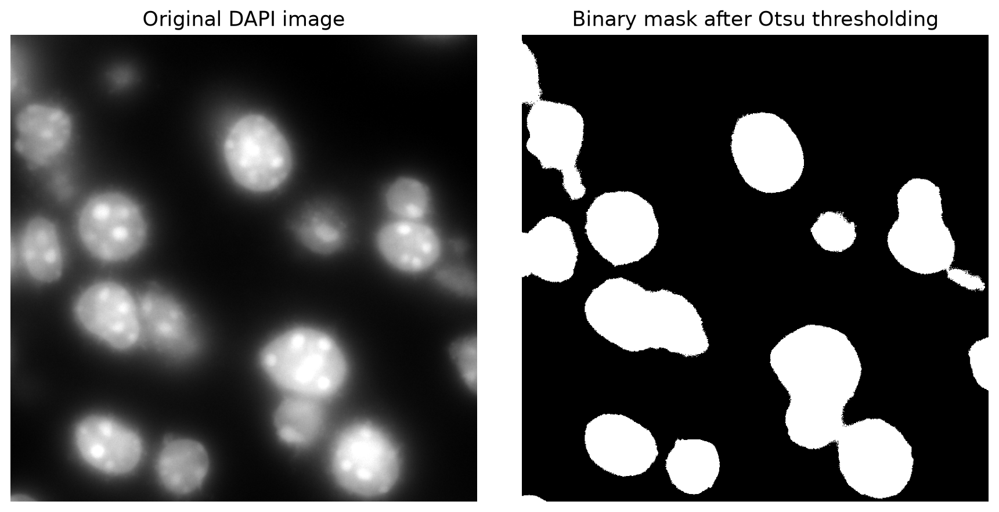

Otsu threshold: 6576


In [111]:
# Start from the actual DAPI image downloaded above.
img = dapi

# Otsu's method finds a foreground/background cutoff automatically.
threshold = ski.filters.threshold_otsu(img)
cells = img > threshold  # True = candidate nuclear pixel

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(dapi_display, cmap='gray')
axes[0].set_title('Original DAPI image')
axes[1].imshow(cells, cmap='gray')
axes[1].set_title('Binary mask after Otsu thresholding')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()
print('Otsu threshold:', threshold)

#### Calculate the distance transform

After thresholding, some nuclei touch and form one white blob. We need additional information to find their separate centers. For each foreground pixel, ndi.distance_transform_edt() calculates its Euclidean distance to the nearest background pixel. Values are therefore smallest near nuclear edges and largest deep inside bright nuclear regions.

The distance map resembles a landscape of hills: each nucleus ideally has a peak near its center. This prepares the image for marker-controlled watershed segmentation. Notice that the distance is measured in pixels, not micrometres, unless the microscope's pixel calibration has been verified.

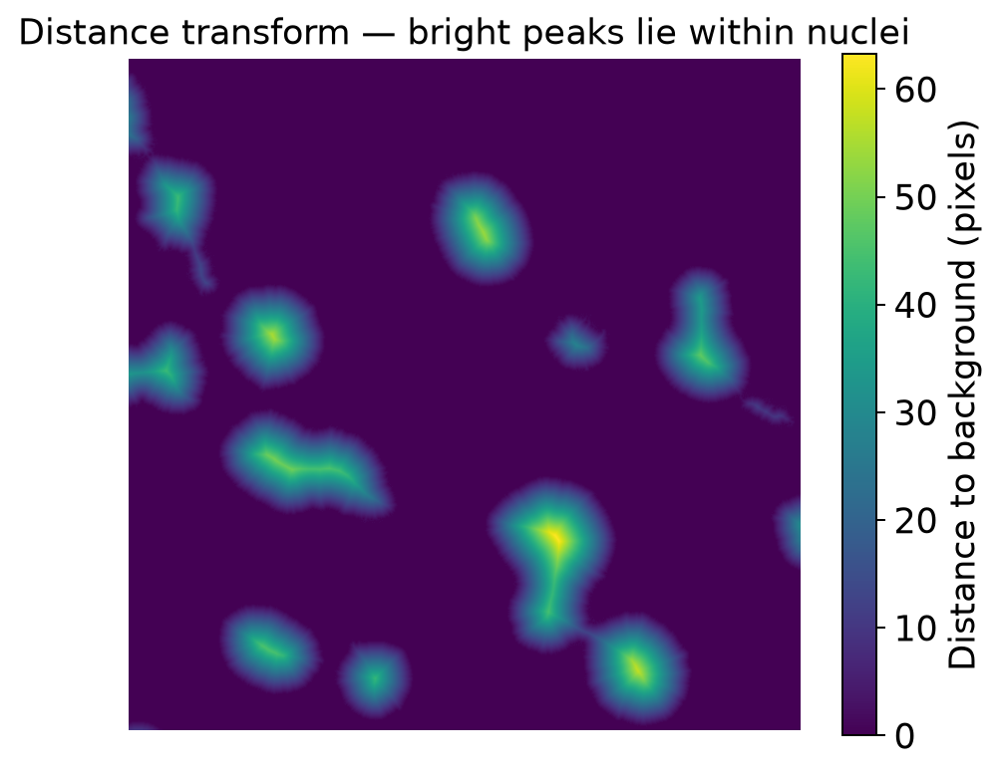

In [112]:
# For foreground pixels, compute distance to the closest background pixel.
distance = ndi.distance_transform_edt(cells)

fig, ax = plt.subplots(figsize=(6, 5))
picture = ax.imshow(distance, cmap='viridis')
fig.colorbar(picture, ax=ax, label='Distance to background (pixels)')
ax.set_title('Distance transform — bright peaks lie within nuclei')
ax.axis('off')
plt.show()

#### Find starting points for individual nuclei

Local maxima are points where the distance map is higher than the surrounding pixels. We use ski.feature.peak_local_max() to detect them. Each detected peak becomes a distinct marker with ski.measure.label(). The watershed algorithm will grow one labeled region from each marker.

The parameter min_distance helps control how closely peaks may occur. If it is too small, we can find several seeds within one nucleus, causing over-segmentation. If it is too large, nearby nuclei may share a single seed, causing under-segmentation. We start with `MIN_SEED_DISTANCE = 25` pixels and will compare the result with the original image.

The three-panel plot below shows how binary mask → distance map → seed points relate to one another. The red dots are seeds, not segmented cell boundaries.

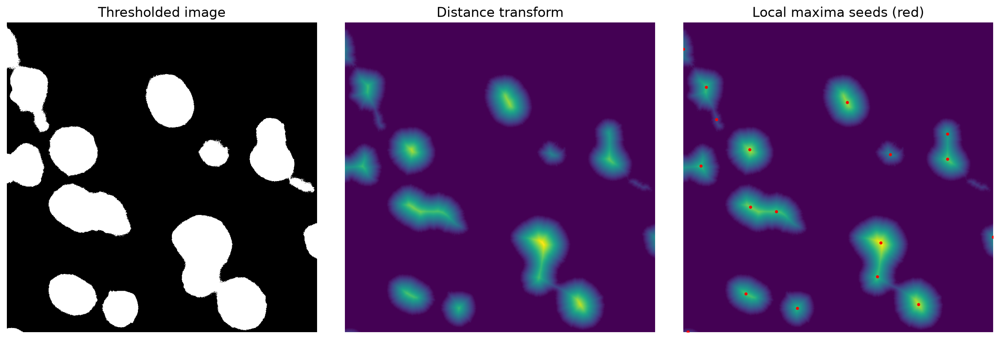

Number of watershed seeds: 18


In [113]:
# Detect local maxima in the distance map and assign unique seed IDs.
MIN_SEED_DISTANCE = 25  # Try 10 or 15 later and compare the result.
local_max_coords = ski.feature.peak_local_max(
    distance, min_distance=MIN_SEED_DISTANCE, exclude_border=False
)
local_max_mask = np.zeros(distance.shape, dtype=bool)
local_max_mask[tuple(local_max_coords.T)] = True
markers = ski.measure.label(local_max_mask)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(cells, cmap='gray')
axes[0].set_title('Thresholded image')
axes[1].imshow(distance, cmap='viridis')
axes[1].set_title('Distance transform')
axes[2].imshow(distance, cmap='viridis')
axes[2].scatter(local_max_coords[:, 1], local_max_coords[:, 0], s=5, c='red')
axes[2].set_title('Local maxima seeds (red)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()
print('Number of watershed seeds:', int(markers.max()))

#### Separate touching nuclei with watershed segmentation

Watershed is analogous to filling separate valleys with water. We provide three ingredients to ski.segmentation.watershed():
- **-distance** — we invert the distance map so the central peaks become valleys where flooding begins.
- **markers** — labeled starting points found in Step 3; each marker receives its own region.
- **mask=cells** — the binary nuclear mask that limits flooding to foreground pixels.
As regions grow, boundaries form where they meet. This can split touching nuclei that thresholding alone considered a single blob. The resulting integer image uses 0 for background and positive integers for distinct nuclear objects.

Compare the colored labels with the DAPI image. Are there clearly two nuclei inside one label? Has a single nucleus been split into separate colors? Those are signs that the threshold and/or seed spacing need adjustment.

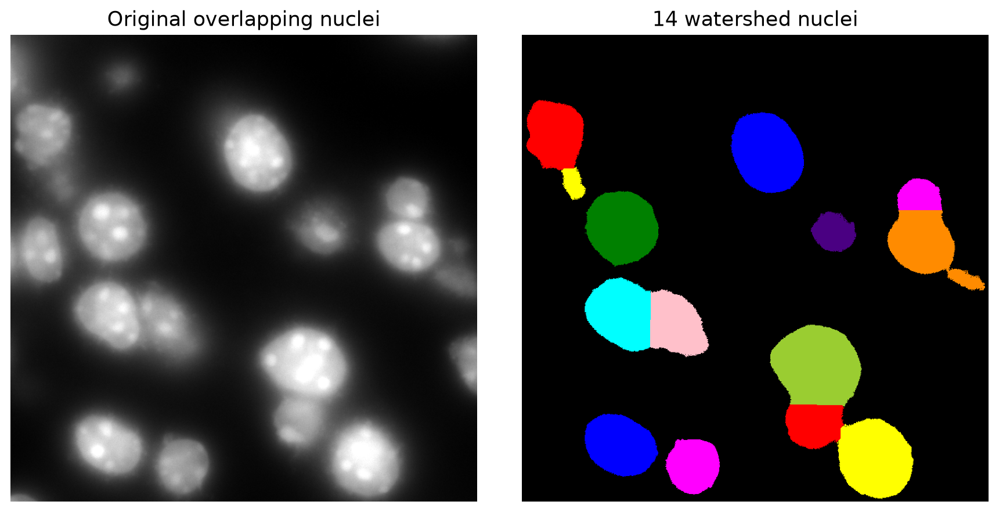

In [114]:
# Grow a separate nuclear region from each seed, restricted to the binary mask.
segmented_cells = ski.segmentation.watershed(-distance, markers, mask=cells)
segmented_cells = ski.segmentation.clear_border(segmented_cells) # remove cells at border
n_cells = len(np.unique(segmented_cells)) - 1  # exclude background label 0

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(dapi_display, cmap='gray')
axes[0].set_title('Original overlapping nuclei')
axes[1].imshow(ski.color.label2rgb(segmented_cells, bg_label=0, bg_color=(0, 0, 0)))
axes[1].set_title(f'{n_cells} watershed nuclei')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

#### Expand nuclear labels towards approximate cell territories

RNA molecules are located in the nucleus and cytoplasm. If we counted only transcripts overlapping nuclear masks, many cytoplasmic molecules would be excluded. One simple approximation is to expand every segmented nuclear label into nearby background pixels using ski.segmentation.expand_labels().

distance=10 limits how far (in pixels) labels can grow. When two expanding regions meet, the function assigns available pixels to the nearer label, so labels do not overlap. Compare the expanded result with the initial watershed segmentation.

Important: Expanded nuclear labels are approximate territories, not empirically measured cell membranes. For higher-quality whole-cell segmentation, imaging experiments often add membrane or cytoplasmic staining and/or use a trained segmentation model. We will not use these approximate regions to reassign molecules in the public AnnData dataset.

**Question:** What biological structures does watershed identify here: nuclei, whole cells, or both? What additional stain or information would help obtain accurate whole-cell boundaries?

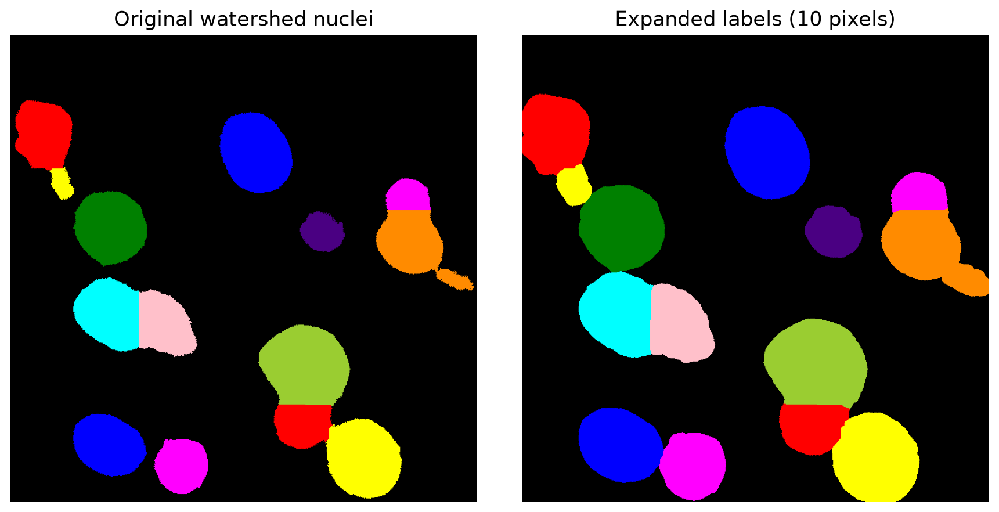

In [115]:
# Grow each nuclear label by at most 10 pixels into available space.
expanded = ski.segmentation.expand_labels(segmented_cells, distance=10)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(ski.color.label2rgb(segmented_cells, bg_label=0, bg_color=(0, 0, 0)))
axes[0].set_title('Original watershed nuclei')
axes[1].imshow(ski.color.label2rgb(expanded, bg_label=0, bg_color=(0, 0, 0)))
axes[1].set_title('Expanded labels (10 pixels)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### Alternative segmentation methods — Cellpose and StarDist

So far, we have used classical image-processing methods to identify
nuclei: thresholding, distance transformation and watershed segmentation.

However, accurately segmenting cells can be challenging, especially
when nuclei overlap, staining intensity varies or cell shapes are irregular.

More advanced segmentation methods use deep learning to identify
individual cells or nuclei directly from microscopy images.

Two widely used tools are:

- **Cellpose** — a deep-learning-based method designed to segment
  cells and nuclei across different microscopy image types.
  [Paper](https://www.nature.com/articles/s41592-020-01018-x)

- **StarDist** — a deep-learning-based method that represents objects
  using star-convex polygons, particularly useful for segmenting nuclei.
  [Paper](https://arxiv.org/abs/1806.03535)

#### Cellpose interactive demo

Explore Cellpose and examples of cell segmentation:

https://www.cellpose.org/

#### Check segmentation quality using object areas

Before trusting segmented objects as cells, we should check whether their sizes are plausible. np.unique(segmented_cells, return_counts=True) counts the number of pixels belonging to each labeled object. We exclude label 0, which represents background, and plot the area distribution.

Very small objects may be noise, staining artefacts or fragments of nuclei. Very large objects may be touching nuclei that were not separated. Both can distort downstream RNA counts and cell annotations.

For this example, we report areas in pixels. In a calibrated experiment, physical nuclear area could be calculated as area_in_pixels × pixel_width_µm × pixel_height_µm. Because we have not independently verified the pixel dimensions of this image plane, we must not convert its area histogram to square micrometres using a pixel size from another dataset.

Look at the histogram and the labeled image together before deciding which objects to filter.

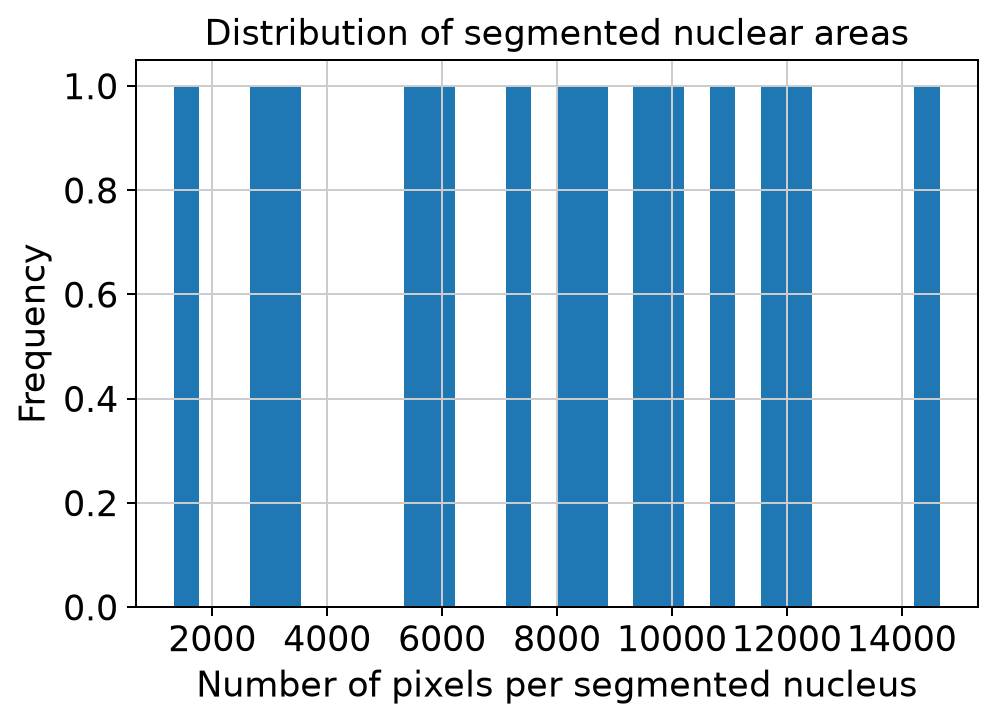

Minimum object area: 1331 pixels
Median object area: 8564 pixels
Maximum object area: 14660 pixels


In [116]:
# Count how many pixels belong to each segmented object.
u, c = np.unique(segmented_cells, return_counts=True)
u = u[1:]  # exclude the background
c = c[1:]

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(c, bins=30)
ax.set(xlabel='Number of pixels per segmented nucleus', ylabel='Frequency',
       title='Distribution of segmented nuclear areas')
plt.show()

print('Minimum object area:', int(c.min()), 'pixels')
print('Median object area:', int(np.median(c)), 'pixels')
print('Maximum object area:', int(c.max()), 'pixels')

#### Remove obvious segmentation artefacts

We now filter the nuclear objects based on the pixel-area histogram. `MIN_AREA` removes objects below the minimum area and `MAX_AREA` removes those above the maximum area. The code below starts at 2,000 and 16,000 pixels, respectively, but you should adjust these thresholds based on the area histogram. These are illustrative thresholds chosen for this particular 750 × 750 pixel crop, not universal dimensions for liver nuclei.

np.isin() identifies all pixels belonging to valid labels. We then construct final_mask in which accepted labels keep their identity and rejected labels become background (0). The three panels let us see precisely which objects were removed.

Adjust the thresholds after looking at the plots. Do large discarded objects represent merged nuclei, or simply bright biological structures? A size filter flags candidates for review, but cannot solve every image-segmentation error.

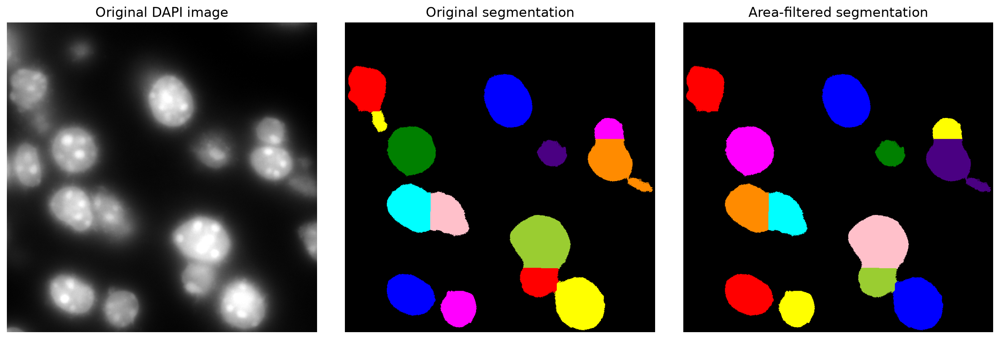

Retained 13 / 14 segmented nuclei.


In [117]:
# Keep only watershed labels within a plausible area range for this crop.
MIN_AREA = 2000 # these values should be changed based on the images
MAX_AREA = 16000
filt = (c > MIN_AREA) & (c < MAX_AREA)
valid_labels = u[filt]

valid_label_mask = np.isin(segmented_cells, valid_labels)
final_mask = np.zeros_like(segmented_cells)
final_mask[valid_label_mask] = segmented_cells[valid_label_mask]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(dapi_display, cmap='gray')
axes[0].set_title('Original DAPI image')
axes[1].imshow(ski.color.label2rgb(segmented_cells, bg_label=0, bg_color=(0, 0, 0)))
axes[1].set_title('Original segmentation')
axes[2].imshow(ski.color.label2rgb(final_mask, bg_label=0, bg_color=(0, 0, 0)))
axes[2].set_title('Area-filtered segmentation')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()
print(f'Retained {len(valid_labels)} / {len(u)} segmented nuclei.')

**Interpretation.** With the example crop and `MIN_SEED_DISTANCE = 25`, the distance-transform approach produces **18 initial seeds**. After watershed and border removal, the displayed mask contains **14 labeled nuclear objects**, of which **13** satisfy the illustrative area limits. These are the outputs of this particular run, not a validated count of cells; changing the crop, threshold or seed spacing will change them.

Compare the DAPI image with the colored labels. Some touching nuclei are separated, while other boundaries remain ambiguous. Thresholding, distance transformation and watershed offer a transparent introduction to image segmentation, but they cannot guarantee accurate nuclei or whole-cell boundaries. Expanding nuclear masks produces approximate territories rather than measured cell membranes.

Filtering by area removes extreme objects but does **not** necessarily improve accuracy: small labels may be fragments or genuine nuclei, and large labels may be merged objects or genuinely large nuclei. This is why manual inspection and more advanced approaches such as Cellpose are worth discussing.

#### Additional segmentation approaches to explore

Classical Otsu thresholding plus watershed is transparent and fast, but more complicated microscopy fields may need other tools.
- **Improve contrast or smooth noise.** ski.filters.gaussian() can reduce pixel-scale noise; a background-correction step can help if illumination varies across the image. Smoothing too strongly may merge nearby nuclei.
- **Clean a binary mask.** ski.morphology.remove_small_objects() discards small isolated regions and remove_small_holes() fills tiny holes. These operate on the binary mask before the distance transform.
- **Use pretrained models.** Cellpose (project and interactive demo) and StarDist use learned image features to identify objects; they can outperform simple intensity thresholds for some images. They require additional software/models and still need quality control.

The following experiment compares the plain Otsu mask with a smoothed and cleaned mask. It does not overwrite cells, distance, markers or segmented_cells, so all subsequent mandatory steps remain reproducible.

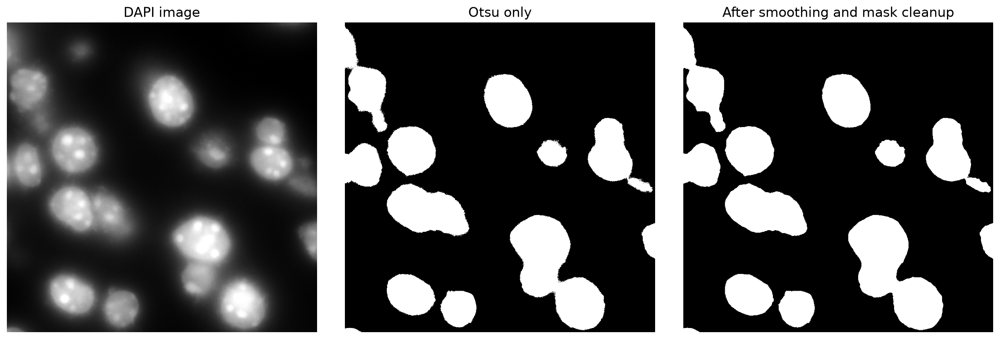

In [118]:
# Explore whether mild smoothing and mask cleanup improve thresholding.
# These variables are separate from the main pipeline.
smoothed = ski.filters.gaussian(img, sigma=1, preserve_range=True)
alternative_threshold = ski.filters.threshold_otsu(smoothed)
alternative_mask = smoothed > alternative_threshold
alternative_mask = ski.morphology.remove_small_objects(alternative_mask, max_size=149)
alternative_mask = ski.morphology.remove_small_holes(alternative_mask, max_size=79)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(dapi_display, cmap='gray')
axes[0].set_title('DAPI image')
axes[1].imshow(cells, cmap='gray')
axes[1].set_title('Otsu only')
axes[2].imshow(alternative_mask, cmap='gray')
axes[2].set_title('After smoothing and mask cleanup')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### Step 5: Quality control of individual cells

The most useful initial measurements are the number of assigned transcript molecules per cell and the number of distinct genes detected per cell. Low counts can indicate inadequate tissue coverage or segmentation, although genuine small cells can also contain fewer molecules.

Mitochondrial fraction is routinely used in scRNA-seq QC, but it is not generally appropriate for this targeted MERFISH panel, which may contain few or no mitochondrial genes.

**Important for reproducibility:** this cell restores the deposited **raw molecule counts** before calculating QC metrics. You can rerun it after normalization without accidentally computing QC on log-transformed values. Rerunning it resets the working `merfish` object; rerun the subsequent cells to regenerate clustering and spatial statistics.

,total_counts,n_genes_by_counts
count,34217.000000,34217.000000
mean,245.445358,51.965865
std,166.959717,17.824886
min,81.000000,14.000000
25%,125.000000,38.000000
50%,192.000000,49.000000
75%,311.000000,63.000000
max,1464.000000,135.000000


Median raw molecules/cell: 192.0
Median detected genes/cell: 49.0


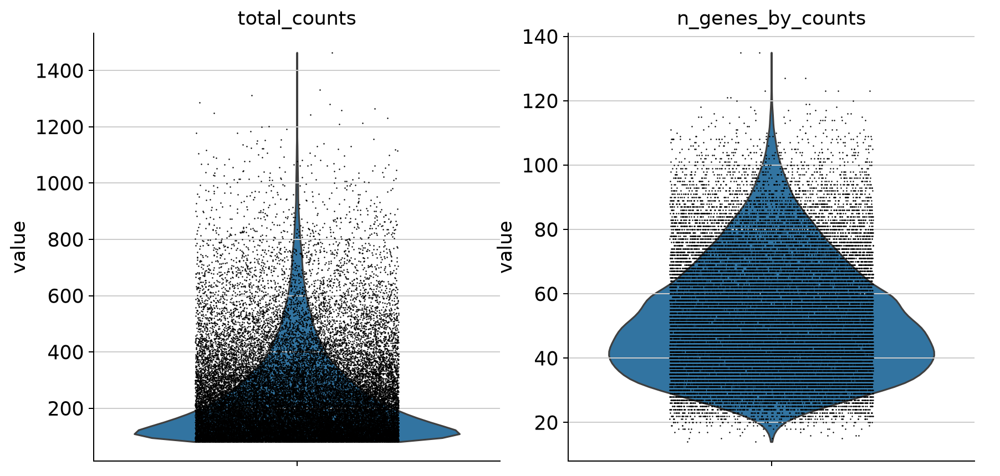

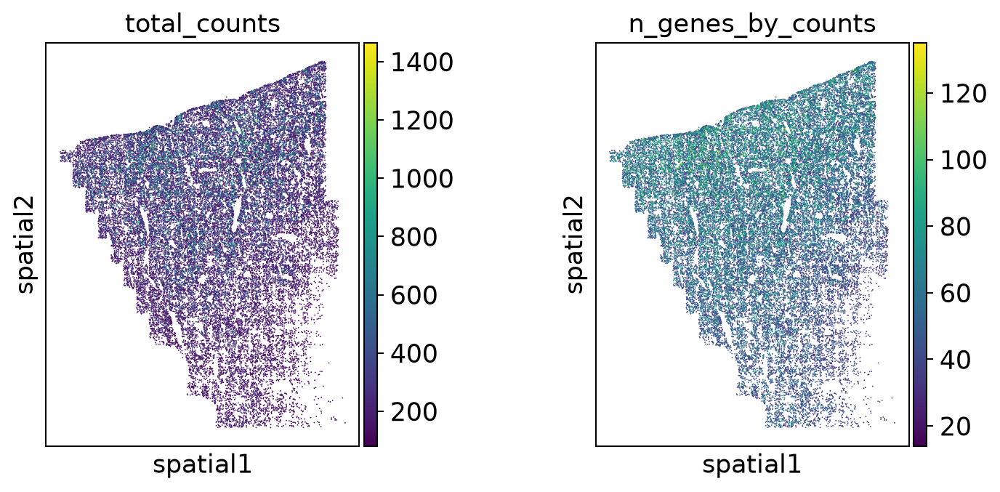

Available segmentation-size metrics: ['area', 'volume']


,area,volume
count,34217.000000,34217.000000
mean,1357.903953,113160.503848
std,644.139574,53679.171194
min,200.119417,16676.889516
25%,851.298536,70942.699065
50%,1257.406462,104785.576404
75%,1793.364873,149449.504329
max,2999.647498,249974.691497


In [119]:
# Restart the MERFISH workflow from the published, unmodified data.
# This prevents notebook cells from using previously normalized expression.
merfish = merfish_published.copy()
merfish.X = merfish_published.layers['counts'].copy()
merfish.layers['counts'] = merfish_published.layers['counts'].copy()
merfish.raw = None
merfish.uns.pop('log1p', None)  # Remove log-transform metadata from the deposited object.
merfish.obs['free_annotation'] = merfish.obs['free_annotation'].astype('category')

sc.pp.calculate_qc_metrics(
    merfish, layer='counts', inplace=True, percent_top=None, log1p=False,
)
display(merfish.obs[['total_counts', 'n_genes_by_counts']].describe())
print('Median raw molecules/cell:', merfish.obs['total_counts'].median())
print('Median detected genes/cell:', merfish.obs['n_genes_by_counts'].median())
sc.pl.violin(merfish, ['total_counts', 'n_genes_by_counts'],
             jitter=0.25, multi_panel=True)

qc_axes = sc.pl.embedding(merfish, basis='spatial',
                          color=['total_counts', 'n_genes_by_counts'],
                          size=2, cmap='viridis', show=False)
for ax in np.atleast_1d(qc_axes).ravel():
    ax.set_aspect('equal')
    ax.invert_yaxis()
plt.show()

area_cols = [c for c in ['area', 'cell_area', 'volume'] if c in merfish.obs.columns]
if area_cols:
    print('Available segmentation-size metrics:', area_cols)
    display(merfish.obs[area_cols].describe())
else:
    print('No cell-area column found; use the available counts and gene metrics.')

**Interpretation.** The clean run contains **34,217 cells** with a median of **192 measured RNA molecules per cell** (range 81–1,464) and **49 detected genes per cell** (range 14–135). The published cell-area field has a median of approximately **1,257** in the dataset's stored area units. These are raw-count QC statistics, not totals recalculated from normalized expression.

The distributions are broad because cell types, sizes, transcript abundances and segmentation quality differ. Extreme values deserve inspection, but a small area or low count alone does not prove a segmentation error. The deposited dataset had also been filtered by its authors before our analysis.

**Question:** Why must we calculate these QC metrics from `layers['counts']`, even if the normalization cell below has already run?

### Step 6: Filter low-count observations

We apply a modest minimum-count threshold; the original paper's preprocessing also used a minimum of 80 counted molecules for its expression analysis. Because this downloadable file is already annotated, some filtering may have been performed upstream. We report how many observations are removed rather than assuming any fixed fraction.

In [120]:
MERFISH_MIN_COUNTS = 80
before_merfish = merfish.n_obs

# QC was calculated on genuine raw counts in the preceding cell.
# Subset by those stored QC values, never by the possibly normalized .X.
cell_keep = merfish.obs['total_counts'] >= MERFISH_MIN_COUNTS
merfish = merfish[cell_keep].copy()

# Similarly, determine gene prevalence from the preserved molecule counts.
raw_counts = merfish.layers['counts']
gene_prevalence = np.asarray((raw_counts > 0).sum(axis=0)).ravel()
merfish = merfish[:, gene_prevalence >= 10].copy()

print('Cells before filtering:', before_merfish)
print('Cells after filtering:', merfish.n_obs)
print('Genes retained:', merfish.n_vars)
print('Fraction of cells retained:', f'{merfish.n_obs / before_merfish:.1%}')

Cells before filtering: 34217
Cells after filtering: 34217
Genes retained: 307
Fraction of cells retained: 100.0%


**Interpretation.** With a minimum of 80 measured molecules per cell, **all 34,217 cells (100%)** and **all 307 panel genes** remain. The minimum count in the annotated file is already 81, consistent with earlier author-side filtering. This does not mean the original imaging experiment contained no segmentation failures or low-count objects; it describes the particular publicly deposited AnnData file.

**Question:** Would a minimum of 80 transcript molecules make sense for Visium capture spots? Why might the two assays require different QC thresholds?

### Step 7: Normalize MERFISH expression

As in the Visium analysis, different transcript totals per observation can dominate raw count values. We normalize each cell to a common library size and apply `log1p`. Because this is a targeted panel, normalized abundances are **not** genome-wide expression levels.

The original molecule counts are preserved in `merfish.layers['counts']`. We **restore `.X` from that layer** every time this code cell runs. Re-executing the cell therefore cannot overwrite the raw counts or log-transform an already log-transformed matrix.

In [121]:
# Reset expression from the untouched original molecule-count layer.
# Safe to rerun: normalization NEVER overwrites layers['counts'].
merfish.X = merfish.layers['counts'].copy()
merfish.uns.pop('log1p', None)
sc.pp.normalize_total(merfish, target_sum=1e4)
sc.pp.log1p(merfish)
merfish.raw = merfish.copy()
print('Normalized/log1p data: merfish.X')
print('Original molecule counts: merfish.layers["counts"]')

Normalized/log1p data: merfish.X
Original molecule counts: merfish.layers["counts"]


**Interpretation.** The expression matrix `merfish.X` now contains normalized, log-transformed panel abundances; `merfish.layers['counts']` still contains the original molecule counts. This transformation helps compare relative expression but does not repair segmentation mistakes or measure genes outside the 307-target panel.

**Quick check:** Rerun only the normalization cell and confirm that `merfish.layers['counts']` stays unchanged and no double-log-transformation occurs.

### Step 8: PCA, UMAP and Leiden clustering

We next identify groups of cells with related gene-expression profiles. In a whole-transcriptome experiment, highly variable genes are typically selected first. Here the MERFISH panel is already targeted and relatively small, so we use all retained panel genes for PCA after scaling the normalized matrix.
- **PCA** summarizes major expression differences across cells.
- **Nearest-neighbor graph** connects cells with similar expression profiles, regardless of their physical positions.
- **UMAP** projects expression similarity into two dimensions.
- **Leiden clustering** defines expression-based cell groups on the neighbor graph.
UMAP coordinates do not represent physical tissue coordinates. We visualize each Leiden group again in its true spatial position to connect molecular identity to anatomy.

/data/leuven/392/vsc39200/conda_envs/regulatory_genomics/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


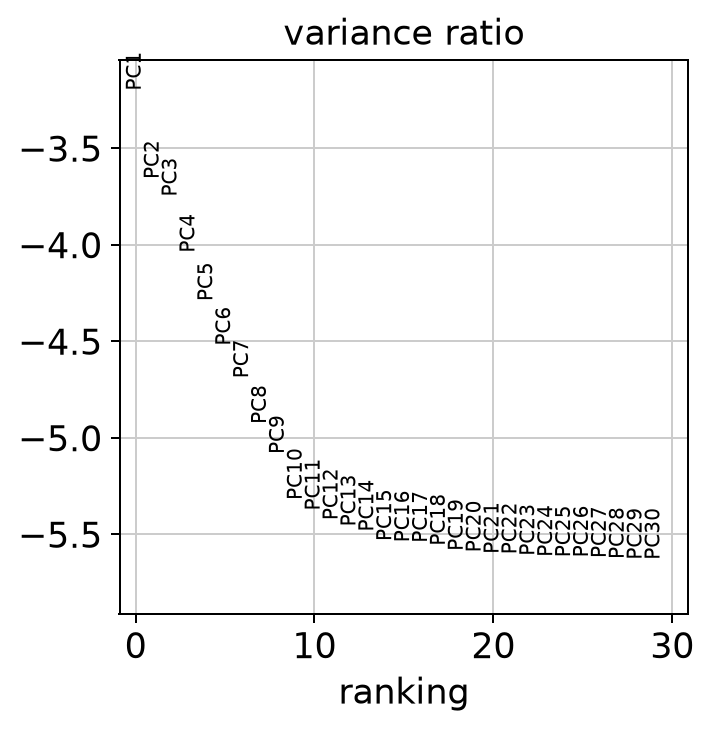

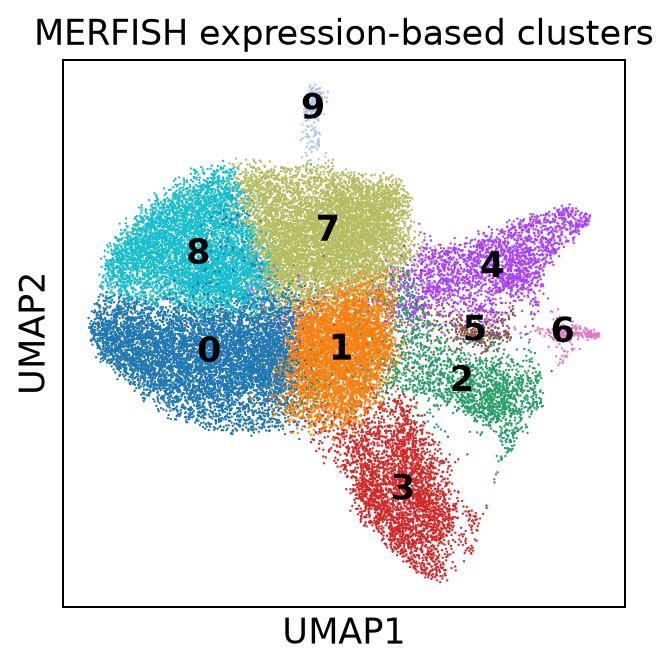

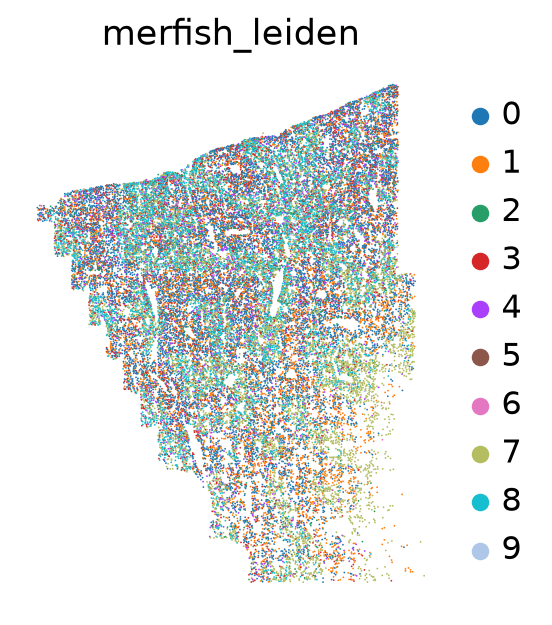

In [122]:
merfish_reduced = merfish.copy()
sc.pp.scale(merfish_reduced, max_value=10)
n_merfish_pcs = min(30, merfish_reduced.n_obs - 1, merfish_reduced.n_vars - 1)
sc.tl.pca(merfish_reduced, n_comps=n_merfish_pcs, svd_solver='arpack')
sc.pl.pca_variance_ratio(merfish_reduced, log=True)
sc.pp.neighbors(merfish_reduced, n_neighbors=15, n_pcs=min(20, n_merfish_pcs))
sc.tl.umap(merfish_reduced, random_state=42)
sc.tl.leiden(merfish_reduced, resolution=0.6,
             key_added='merfish_leiden', flavor='igraph', directed=False)

merfish.obs['merfish_leiden'] = merfish_reduced.obs['merfish_leiden'].copy()
merfish.obsm['X_umap'] = merfish_reduced.obsm['X_umap'].copy()

sc.pl.umap(merfish, color='merfish_leiden', legend_loc='on data',
           title='MERFISH expression-based clusters')
axes = sc.pl.embedding(merfish, basis='spatial', color='merfish_leiden',
                       size=2, frameon=False, show=False)
axes.set_aspect('equal')
axes.invert_yaxis()
plt.show()

**Interpretation.** Using the 307-gene MERFISH panel, PCA followed by a 15-neighbor expression graph and Leiden clustering at resolution 0.6 identifies **10 expression-defined clusters (0–9)**. UMAP brings cells with similar measured expression together; it is **not a map of the tissue**. Compare the UMAP with the second plot, which places the same clusters back at their measured tissue coordinates.

The cluster numbers are arbitrary identifiers and need independent biological annotation. The published cell-type labels and marker genes in Step 10 provide that comparison.

**Question:** If two groups are far apart in UMAP space, does that mean those cells are physically far apart in the liver?

### Step 9: Highlight clusters in the tissue

We can draw all measured cells in light gray and highlight one expression-defined cluster in red. This illustrates where that cluster is concentrated. We then enlarge a local field of view. Cluster IDs are specific to the preprocessing and Leiden settings. The code highlights the two largest clusters found in your run.

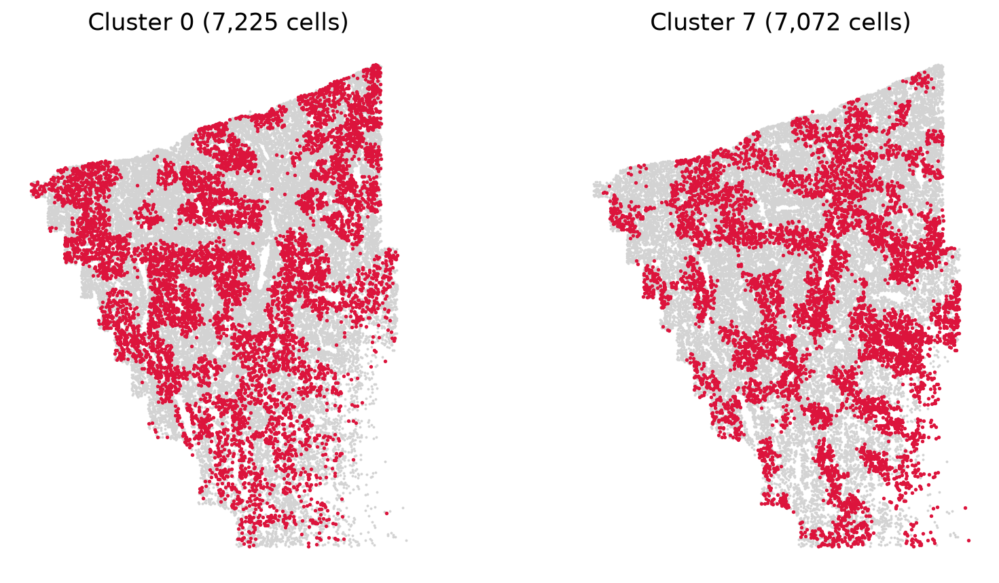

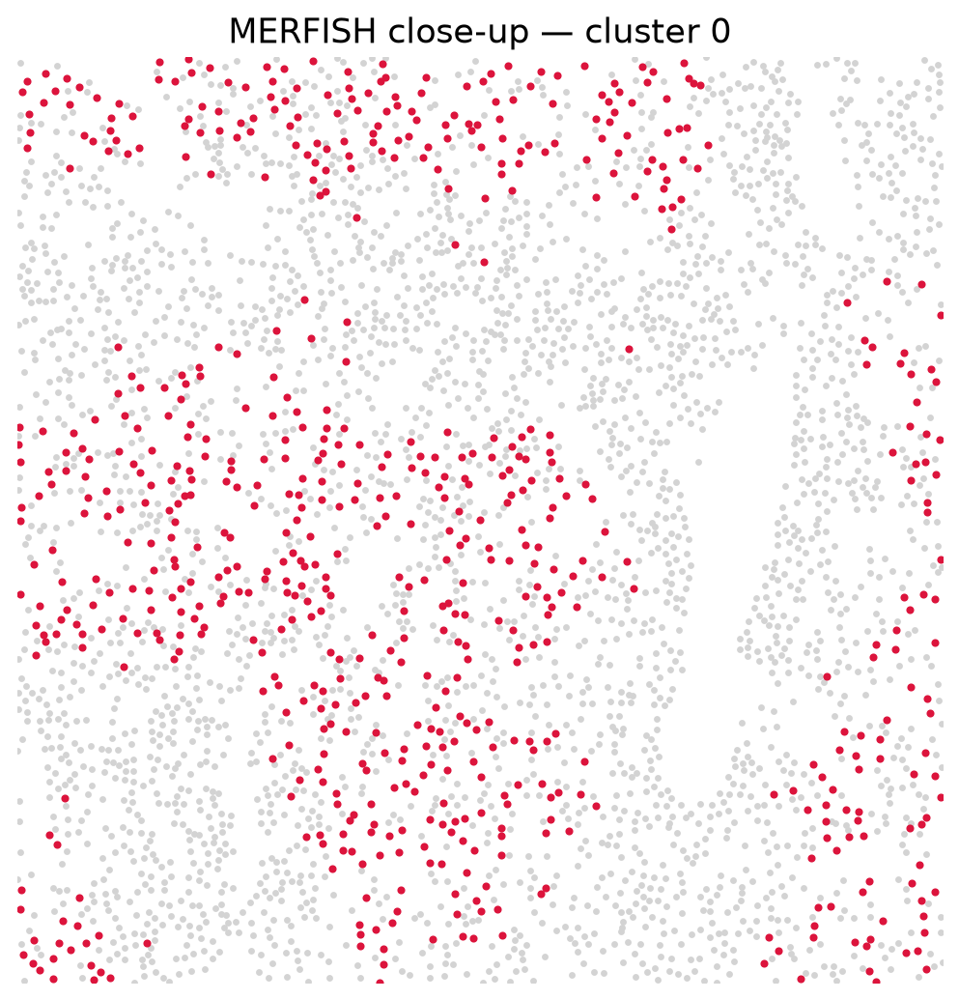

Edit MERFISH_ZOOM_CENTER and MERFISH_ZOOM_HALF_WIDTH to explore another area.


In [123]:
merfish_xy = np.asarray(merfish.obsm['spatial'], dtype=float)
cluster_labels = merfish.obs['merfish_leiden'].astype(str).to_numpy()
all_clusters = pd.Series(cluster_labels).value_counts()
MERFISH_HIGHLIGHT_CLUSTERS = all_clusters.index[:2].tolist()

fig, axes = plt.subplots(1, len(MERFISH_HIGHLIGHT_CLUSTERS),
                         figsize=(5 * len(MERFISH_HIGHLIGHT_CLUSTERS), 5))
for ax, cluster in zip(np.atleast_1d(axes), MERFISH_HIGHLIGHT_CLUSTERS):
    selected = cluster_labels == cluster
    ax.scatter(merfish_xy[:, 0], merfish_xy[:, 1], s=0.3, color='lightgray', rasterized=True)
    ax.scatter(merfish_xy[selected, 0], merfish_xy[selected, 1],
               s=1.3, color='crimson', rasterized=True)
    ax.set_title(f'Cluster {cluster} ({selected.sum():,} cells)')
    ax.set_aspect('equal')
    ax.invert_yaxis()
    ax.axis('off')
plt.tight_layout()
plt.show()

# Zoom around an actual cell from the first highlighted cluster.
selected_xy = merfish_xy[cluster_labels == MERFISH_HIGHLIGHT_CLUSTERS[0]]
candidate_center = np.median(selected_xy, axis=0)
MERFISH_ZOOM_CENTER = selected_xy[np.argmin(np.linalg.norm(selected_xy - candidate_center, axis=1))]
MERFISH_ZOOM_HALF_WIDTH = 0.10 * np.max(np.ptp(merfish_xy, axis=0))
in_zoom = ((np.abs(merfish_xy[:, 0] - MERFISH_ZOOM_CENTER[0]) <= MERFISH_ZOOM_HALF_WIDTH) &
           (np.abs(merfish_xy[:, 1] - MERFISH_ZOOM_CENTER[1]) <= MERFISH_ZOOM_HALF_WIDTH))
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(merfish_xy[in_zoom, 0], merfish_xy[in_zoom, 1],
           s=3, color='lightgray', rasterized=True)
focus = in_zoom & (cluster_labels == MERFISH_HIGHLIGHT_CLUSTERS[0])
ax.scatter(merfish_xy[focus, 0], merfish_xy[focus, 1],
           s=5, color='crimson', rasterized=True)
ax.set(xlim=(MERFISH_ZOOM_CENTER[0] - MERFISH_ZOOM_HALF_WIDTH, MERFISH_ZOOM_CENTER[0] + MERFISH_ZOOM_HALF_WIDTH),
       ylim=(MERFISH_ZOOM_CENTER[1] - MERFISH_ZOOM_HALF_WIDTH, MERFISH_ZOOM_CENTER[1] + MERFISH_ZOOM_HALF_WIDTH),
       title=f'MERFISH close-up — cluster {MERFISH_HIGHLIGHT_CLUSTERS[0]}')
ax.set_aspect('equal')
ax.invert_yaxis()
ax.axis('off')
plt.show()
print('Edit MERFISH_ZOOM_CENTER and MERFISH_ZOOM_HALF_WIDTH to explore another area.')

The plotting code selects two of the largest Leiden clusters present in **your** run, so it works even if cluster numbers change. Red points show the actual tissue locations of the selected cells against all other cells in gray. The zoom changes the view, not the segmentation or the cell annotations, and must not be interpreted as a raw microscopy image.

### Step 10: Compare clusters with cell-type annotations

Cluster labels are initially numbers; their biological meaning must come from marker genes and independent annotations. We rank genes enriched in each Leiden cluster, then compare the clusters with free_annotation, the authors' annotated liver cell types.

Examples from the study include Cyp2f2 for periportal-associated hepatocytes, Ptprb for endothelial cells and Clec4f for Kupffer cells. Because this is a targeted panel, some commonly used genes may not be present; the plotting code checks gene availability.

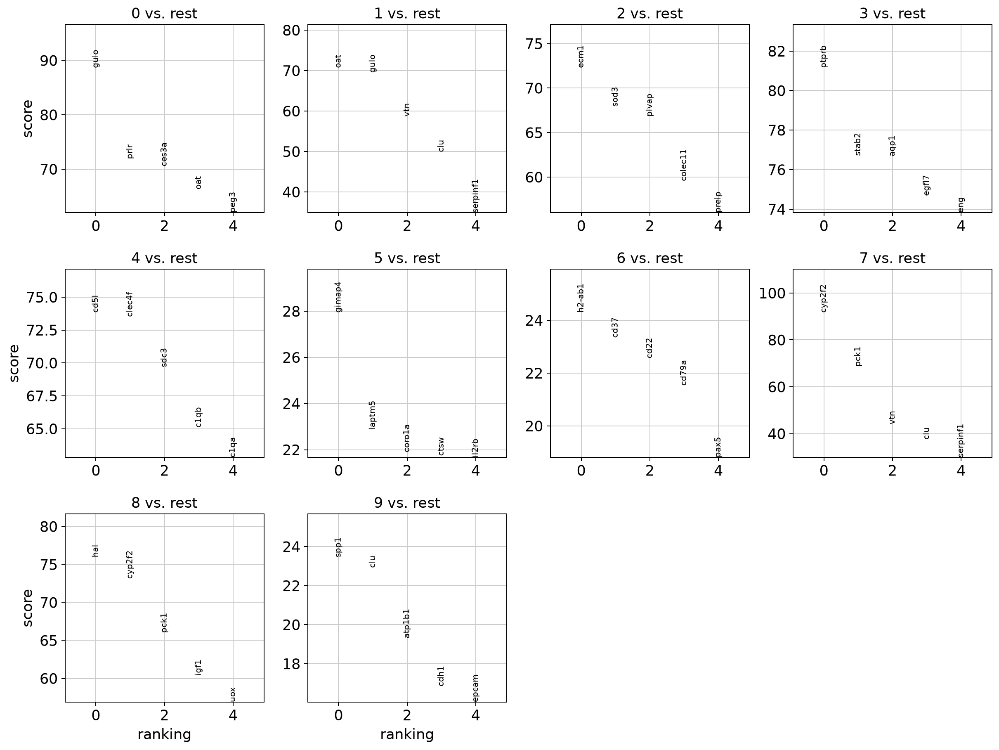

free_annotation,Kupffer cell,bile duct epithelial cell,hepatic stellate cell,immune cell,pericentral endothelial cell,pericentral hepatocyte,periportal endothelial cell,periportal hepatocyte
merfish_leiden,,,,,,,,
0,0.00,0.0,0.00,0.00,0.00,0.91,0.00,0.09
1,0.00,0.0,0.00,0.00,0.00,0.93,0.00,0.06
2,0.02,0.0,0.70,0.00,0.00,0.17,0.01,0.10
3,0.00,0.0,0.00,0.00,0.43,0.06,0.45,0.05
4,0.85,0.0,0.01,0.02,0.00,0.06,0.00,0.06
5,0.29,0.0,0.05,0.12,0.05,0.15,0.06,0.29
6,0.22,0.0,0.03,0.28,0.05,0.22,0.05,0.16
7,0.01,0.0,0.00,0.00,0.00,0.05,0.00,0.94
8,0.01,0.0,0.00,0.00,0.00,0.03,0.00,0.96


,Largest published cell type,Fraction of cluster (%)
merfish_leiden,,
0,pericentral hepatocyte,90.9
1,pericentral hepatocyte,93.5
2,hepatic stellate cell,69.8
3,periportal endothelial cell,45.4
4,Kupffer cell,84.7
5,periportal hepatocyte,29.3
6,immune cell,27.6
7,periportal hepatocyte,94.2
8,periportal hepatocyte,96.3


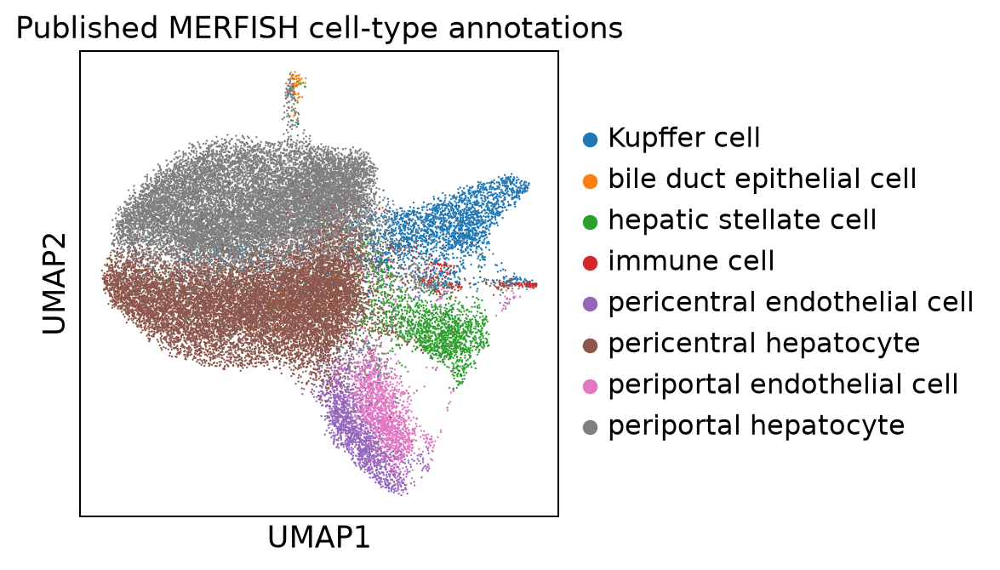

Available marker genes: ['cyp2f2', 'ptprb', 'clec4f', 'hmgcs2', 'krt19']


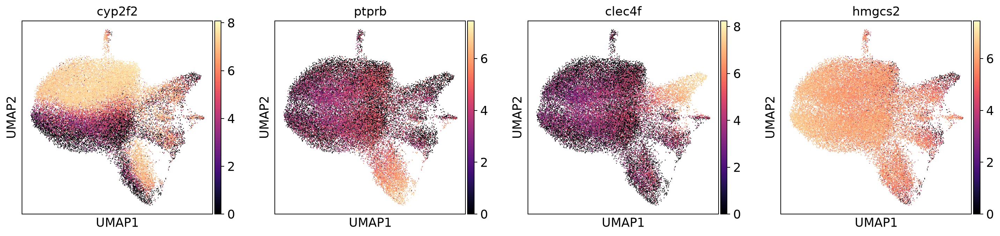

In [124]:
sc.tl.rank_genes_groups(merfish, groupby='merfish_leiden',
                       method='wilcoxon', use_raw=False)
sc.pl.rank_genes_groups(merfish, n_genes=5, sharey=False)

comparison = pd.crosstab(merfish.obs['merfish_leiden'],
                          merfish.obs['free_annotation'],
                          normalize='index')
display(comparison.round(2))

# Report each cluster's leading published annotation without assuming that
# cluster IDs or percentages are stable across preprocessing choices.
cluster_summary = pd.DataFrame({
    'Largest published cell type': comparison.idxmax(axis=1),
    'Fraction of cluster (%)': (100 * comparison.max(axis=1)).round(1),
})
display(cluster_summary)

sc.pl.umap(merfish, color='free_annotation',
           title='Published MERFISH cell-type annotations')

merfish_gene_lookup = {str(g).lower(): str(g) for g in merfish.var_names}
def merfish_available(gene_names):
    # Match mouse gene symbols against panel names without regard to case.
    return [merfish_gene_lookup[g.lower()] for g in gene_names
            if g.lower() in merfish_gene_lookup]

marker_genes = merfish_available(['Cyp2f2', 'Ptprb', 'Clec4f', 'Hmgcs2', 'Krt19'])
print('Available marker genes:', marker_genes)
if marker_genes:
    sc.pl.umap(merfish, color=marker_genes[:4], cmap='magma')

**Interpretation.** Comparison with the independently published `free_annotation` labels recovers recognizable liver populations from the targeted expression panel:

- **Clusters 0 and 1** are **90.9% and 93.5% pericentral hepatocytes**.
- **Clusters 7 and 8** are **94.2% and 96.3% periportal hepatocytes**.
- **Cluster 4** is **84.7% Kupffer cells**, consistent with markers such as *Clec4f*.
- **Cluster 2** is **69.8% hepatic stellate cells**.
- **Cluster 3** contains a mix of periportal and pericentral endothelial cells (approximately **45% and 43%**, respectively).

Clusters 5 and 6 are more heterogeneous, illustrating how unsupervised clusters may merge multiple related populations or cell states. Percentages are calculated **within each Leiden cluster** (rows of the contingency table), not across the whole liver. These numbers describe the provided clean run at the stated parameters; they can shift if you change filtering or clustering settings.

**Question:** Why might endothelial populations be grouped together even though the published annotations distinguish periportal and pericentral locations?

### Step 11: Map liver markers and zonation genes

We can now plot selected genes at their actual cell coordinates. The key liver-zonation distinction is between cells nearer portal regions and those nearer central veins. The Liu et al. analysis distinguishes periportal and pericentral hepatocyte populations using gene expression and their tissue distributions.

Examples from the paper include Cyp2f2, Pck1, Hal and Cdh1 as periportal-associated markers. Genes such as Glul and Cyp2e1 are commonly associated with pericentral hepatocytes. We check which candidates were included in the targeted 307-gene panel before plotting.

Remember that a spatial pattern in a cell-level MERFISH map is different from an expression overlay in Visium, where one capture spot can include several cells.

Periportal candidates present: ['cyp2f2', 'pck1', 'hal', 'cdh1']
Pericentral candidates present: ['glul']


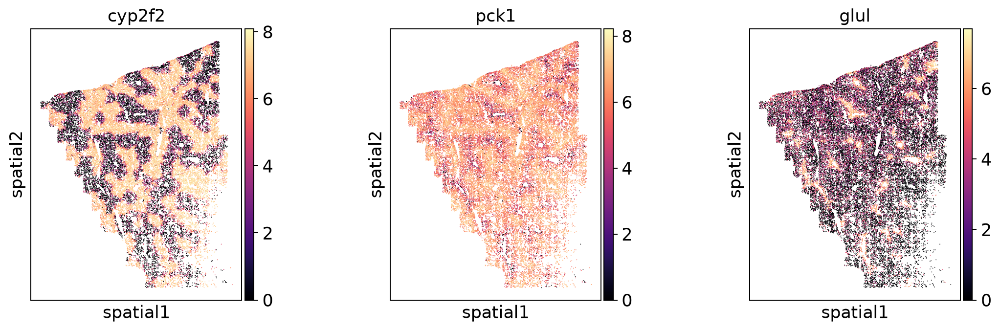

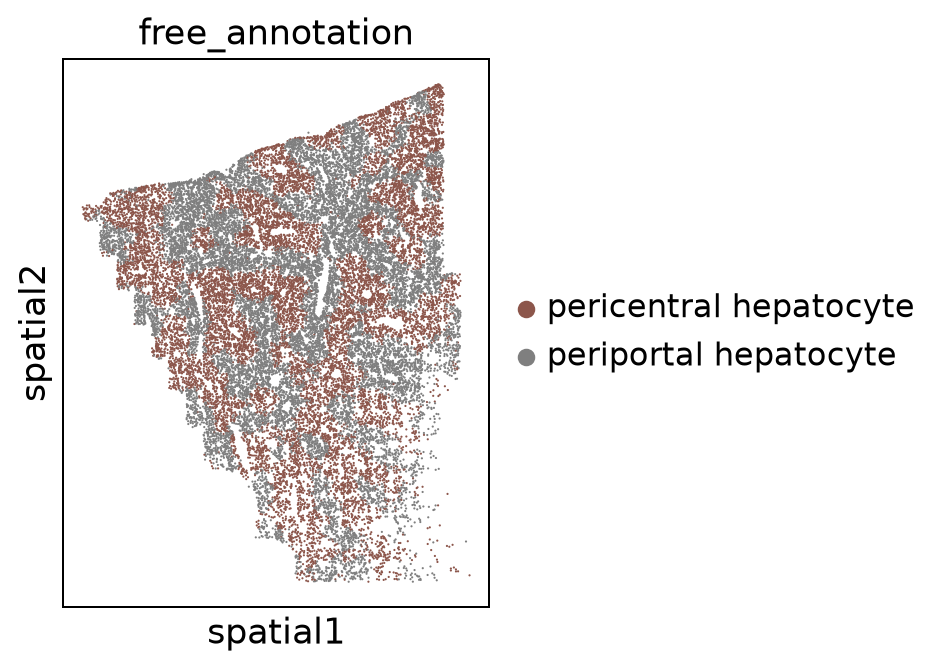

In [125]:
# Define the lookup here as well, so this section does not depend on
# a helper having been created in an earlier optional analysis cell.
merfish_gene_lookup = {str(g).lower(): str(g) for g in merfish.var_names}
def merfish_available(gene_names):
    return [merfish_gene_lookup[g.lower()] for g in gene_names
            if g.lower() in merfish_gene_lookup]

periportal_genes = merfish_available(['Cyp2f2', 'Pck1', 'Hal', 'Cdh1', 'Sds'])
pericentral_genes = merfish_available(['Glul', 'Cyp2e1', 'Cyp1a2', 'Axin2'])
print('Periportal candidates present:', periportal_genes)
print('Pericentral candidates present:', pericentral_genes)

zonation_merfish = list(dict.fromkeys(periportal_genes[:2] + pericentral_genes[:2]))
if zonation_merfish:
    axes = sc.pl.embedding(merfish, basis='spatial', color=zonation_merfish,
                           size=2, cmap='magma', show=False)
    for ax in np.atleast_1d(axes).ravel():
        ax.set_aspect('equal')
        ax.invert_yaxis()
    plt.show()

hepatocyte_groups = [x for x in merfish.obs['free_annotation'].cat.categories
                     if 'hepatocyte' in str(x).lower()]
if hepatocyte_groups:
    hepatocytes = merfish[merfish.obs['free_annotation'].isin(hepatocyte_groups)].copy()
    axes = sc.pl.embedding(hepatocytes, basis='spatial',
                           color='free_annotation', size=3, show=False)
    axes.set_aspect('equal')
    axes.invert_yaxis()
    plt.show()

The periportal-associated genes cyp2f2, pck1, hal and cdh1 were detected in this panel; among the tested pericentral candidates, glul was available. Their tissue maps can therefore directly compare spatially patterned hepatocyte programs. The second plot uses the authors' annotations to contrast the 14,083 periportal with 12,708 pericentral hepatocytes. Cyp2e1 was not among the available tested pericentral markers here, so do not interpret its absence from the plot as absence of pericentral cells.

### Step 12: Identify spatially autocorrelated genes

A gene may vary between cells without showing an organized distribution in the tissue. Moran's I measures whether nearby cells have unusually similar expression values. Positive scores indicate spatial clustering of expression; scores around zero indicate little spatial autocorrelation at the measured neighborhood scale.

We first build a physical neighbor graph from cell coordinates. This differs from the expression-neighbor graph used earlier for PCA/UMAP/Leiden.

INFO     Creating graph using `None` transform and `1` libraries.                                                  


100%|██████████| 100/100 [00:05<00:00, 19.66/s]


,I,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
cyp2f2,0.764653,0.000000e+00,0.000009,0.0,0.009901,0.000017,0.000000e+00,0.0,0.009901
pck1,0.370975,0.000000e+00,0.000009,0.0,0.009901,0.000013,0.000000e+00,0.0,0.009901
glul,0.321235,0.000000e+00,0.000009,0.0,0.009901,0.000011,0.000000e+00,0.0,0.009901
hmgcs2,0.087638,0.000000e+00,0.000009,0.0,0.009901,0.000007,0.000000e+00,0.0,0.009901
clec4f,0.078308,0.000000e+00,0.000009,0.0,0.009901,0.000005,0.000000e+00,0.0,0.009901
ptprb,0.041284,0.000000e+00,0.000009,0.0,0.009901,0.000005,0.000000e+00,0.0,0.009901
krt19,0.019897,1.408396e-11,0.000009,0.0,0.009901,0.000004,1.408396e-11,0.0,0.009901


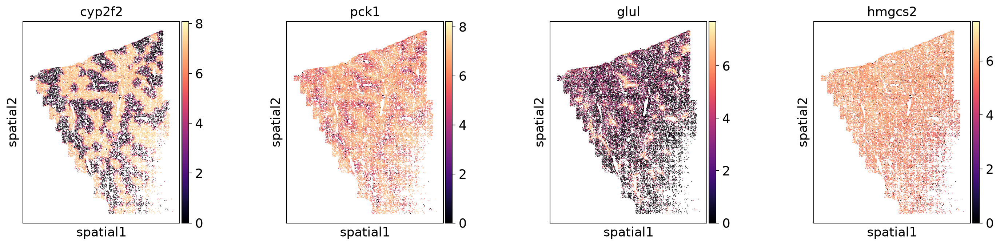

In [126]:
sq.gr.spatial_neighbors_knn(merfish, n_neighs=6)
moran_candidates = list(dict.fromkeys(zonation_merfish + marker_genes))
if moran_candidates:
    sq.gr.spatial_autocorr(merfish, mode='moran', genes=moran_candidates,
                          n_perms=100, n_jobs=1, seed=42)
    display(merfish.uns['moranI'].head(12))
    top_genes = [g for g in merfish.uns['moranI'].head(4).index
                 if g in merfish.var_names]
    if top_genes:
        axes = sc.pl.embedding(merfish, basis='spatial', color=top_genes,
                               size=2, cmap='magma', show=False)
        for ax in np.atleast_1d(axes).ravel():
            ax.set_aspect('equal')
            ax.invert_yaxis()
        plt.show()
else:
    print('No selected marker genes present. Expand the candidate list.')

**Interpretation.** Moran's I reveals a strong spatially structured zonation signal in this targeted MERFISH panel. The leading tested genes are:

- ***Cyp2f2* — I = 0.765**, the strongest spatial association among the selected genes.
- ***Pck1* — I = 0.371** and ***Glul* — I = 0.321**, both displaying spatially localized expression consistent with liver zonation.
- *Hmgcs2* (0.088), *Clec4f* (0.078), *Ptprb* (0.041) and *Krt19* (0.020) have weaker autocorrelation on the same six-nearest-cell graph.

These results fit the broad periportal/pericentral organization observed in the tissue maps. Importantly, **Moran's I reports spatial organization, not direction along a portal–central axis**, and only the selected marker genes were tested here. With 100 permutations, empirical p-values have limited resolution; the smallest possible nonzero permutation p-value is about 0.0099.

**Question:** Can a gene show a strong difference between two cell types but a low Moran's I? What spatial arrangement of those cell types could produce this?

### Step 13: Spatial neighborhood enrichment

Imaging-based data allow us to study which annotated cell populations tend to be physically adjacent to one another. Squidpy's neighborhood enrichment compares observed neighboring cell-type pairs with pairs expected when cell-type labels are permuted.

Here we use real MERFISH cell coordinates together with the published liver cell annotations.

Positive enrichment can arise from shared anatomical niches (such as hepatocytes and sinusoidal endothelial cells); it is not direct evidence of cell-cell signaling.

100%|██████████| 100/100 [00:00<00:00, 357.35/s]


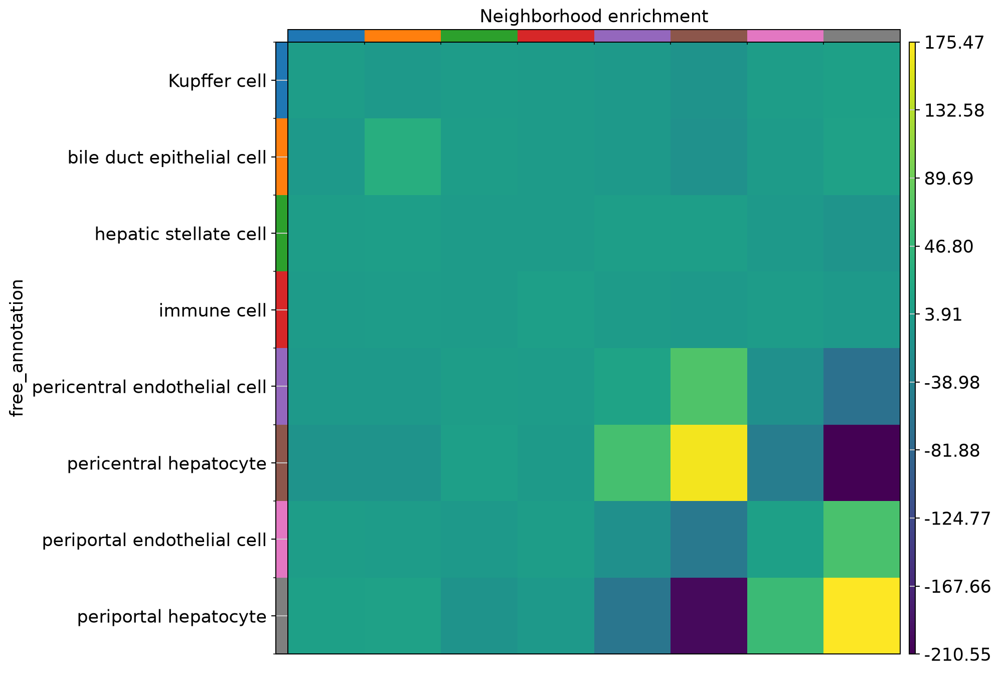

In [127]:
sq.gr.nhood_enrichment(merfish, cluster_key='free_annotation',
                      n_perms=100, seed=42)
sq.pl.nhood_enrichment(merfish, cluster_key='free_annotation',
                      figsize=(9, 7))

The heatmap uses the published cell annotations and the actual positions of the 34,217 segmented cells. Red/positive values indicate pairs found together more frequently than in 100 shuffled-label permutations, while blue/negative values indicate relative avoidance. Since hepatocytes make up most cells, interpret enrichment relative to the permutation baseline, not simply relative to raw cell counts. Adjacency alone does not establish signaling.

### Step 14: Save the processed MERFISH analysis

Save the AnnData object with normalized expression, raw molecule counts in layers["counts"], spatial coordinates, cell annotations, Leiden clusters and spatial analysis results. This allows the same processed dataset to be loaded in a future session without repeating the analysis.

In [128]:
MERFISH_RESULT = RESULTS / 'merfish_mouse_liver_processed.h5ad'
merfish.write_h5ad(MERFISH_RESULT, compression='gzip')
print('Saved MERFISH analysis:', MERFISH_RESULT)
print('Size:', round(MERFISH_RESULT.stat().st_size / 1e6, 1), 'MB')

Saved MERFISH analysis: /lustre1/project/stg_00002/lcb/gmoro/regulatory_genomics_course/results/spatial_liver/merfish_mouse_liver_processed.h5ad
Size: 32.4 MB


# Part 3: Imaging-based spatial transcriptomics (Resolve Molecular Cartography)

## Biological context and the published spatial dataset

The mammalian liver is organized along a portal-to-central axis. Hepatocytes close to the central vein express characteristic genes such as Glul, whereas cells toward the portal tract show a different metabolic program, including genes such as Cps1. Between these extremes are intermediate cell states, which can be characterized using genes such as Cyp2e1. The relevant structures and cell populations are introduced at the beginning of this notebook.

In this section we explore the imaging-based dataset generated by [Bravo González-Blas et al., Nature Cell Biology (2024)](https://doi.org/10.1038/s41556-023-01316-4), Single-cell spatial multi-omics and deep learning dissect enhancer-driven gene regulatory networks in liver zonation.

The authors used Resolve Biosciences Molecular Cartography, a multiplexed fluorescence in situ hybridization method. They measured a 100-gene panel in liver sections from three mice and identified spatially patterned hepatocyte states together with other liver cell types. The downloadable `Resolve_Liver.loom` used here contains **15,522 cells and 98 measured genes**. This processed public file can differ from cell/gene counts given for the original experimental panel in the publication.

Importantly, this is not MERFISH. Resolve Molecular Cartography and MERFISH are both imaging-based technologies, but they use distinct probe/readout schemes. We use this third dataset to reinforce the same analytical concepts on an independent example and to compare spatial patterns across technologies.

The DOI above and the SCope collection linked below provide the publication and dataset context.

## Resolve workflow

### Step 0: Obtain the Resolve file

Unlike the MERFISH .h5ad, the published Resolve file is distributed via the [Scope liver collection](https://scope.aertslab.org/#/Bravo_et_al_Liver). Open that website, expand Spatial in the left-hand dataset list and use the download icon alongside Resolve_Liver.

Download precisely Resolve_Liver.loom. The similarly named Reference_Free_ScoMAP_RNA_MO and Reference_Free_ScoMAP_ATAC_MO files contain computationally mapped expression and accessibility, rather than the originally measured spatial RNA signal. Likewise, Liver-cell_gene-all-2.loom under ATAC contains gene activities and is not an imaging dataset.

Place the downloaded file alongside the notebook in the `PROJECT` directory printed in Step 0 (or change `PROJECT` once at the beginning). The analysis deliberately does not invent a direct SCope download URL; file access is performed through the published download control.

In [129]:
# Download Resolve_Liver.loom from SCope > Bravo_et_al_Liver > Spatial.
# Put it in PROJECT alongside this notebook (or edit PROJECT in Step 0).
RESOLVE_FILE = PROJECT / 'Resolve_Liver.loom'

print('Looking for:', RESOLVE_FILE)
if not RESOLVE_FILE.is_file():
    raise FileNotFoundError(
        f'Cannot find {RESOLVE_FILE}. Place Resolve_Liver.loom in PROJECT, '
        'or update PROJECT in the setup cell to point to your notebook folder.'
    )
print('File size:', round(RESOLVE_FILE.stat().st_size / 1e6, 1), 'MB')

Looking for: /lustre1/project/stg_00002/lcb/gmoro/regulatory_genomics_course/Resolve_Liver.loom
File size: 4.6 MB


### Step 1: Read the SCope Loom file and coordinates

The Loom format stores a gene-by-cell matrix, metadata attached to cells and genes, and sometimes multiple two-dimensional embeddings. SCope uses the metadata name Spatial for the real tissue coordinates; it also stores a different Seurat UMAP representation, which is a low-dimensional projection of expression similarity.

We use h5py to read the SCope-specific embedding and metadata fields explicitly. This avoids accidentally plotting a UMAP as if it were anatomical coordinates. The available fields and embedding names are printed so that they can be checked against the downloaded file.

[Loom specification](https://linnarssonlab.org/loompy/format/)

In [130]:
import json
import base64
import zlib
import h5py
import numpy as np
import pandas as pd
import anndata as ad


def _as_text(values):
    return [
        x.decode("utf-8", errors="replace") if isinstance(x, bytes)
        else str(x)
        for x in values
    ]


def _scopecoordinate_column(dataset, embedding_id):
    """Read coordinates from a SCope embedding dataset."""

    arr = dataset[()]

    if arr.dtype.names:
        field = str(embedding_id)

        if field not in arr.dtype.names:
            raise KeyError(
                f"Embedding ID {field} is not in {arr.dtype.names}"
            )

        return np.asarray(arr[field], dtype=float)

    if arr.ndim == 2:
        return np.asarray(arr[:, embedding_id], dtype=float)

    raise ValueError(
        "Unexpected SCope embedding representation: "
        + str(arr.shape)
    )


# -------------------------------------------------------
# 1. Read the expression matrix and cell annotations
# -------------------------------------------------------

with h5py.File(RESOLVE_FILE, "r") as loom:

    ca = loom["col_attrs"]
    ra = loom["row_attrs"]

    print("Cell attributes:", list(ca.keys()))
    print("Gene attributes:", list(ra.keys()))

    gene_key = next(
        (
            k for k in ("Gene", "GeneName", "GeneNames", "gene")
            if k in ra
        ),
        None
    )

    cell_key = next(
        (
            k for k in ("CellID", "CellId", "cell_id")
            if k in ca
        ),
        None
    )

    if gene_key is None or cell_key is None:
        raise KeyError(
            "Gene or cell identifiers missing. "
            "Inspect the attributes printed above."
        )

    genes = _as_text(ra[gene_key][()])
    cell_ids = _as_text(ca[cell_key][()])

    # Loom stores genes x cells.
    # AnnData expects cells x genes.
    expression = np.asarray(
        loom["matrix"][()],
        dtype=np.float32
    ).T

    assert expression.shape == (len(cell_ids), len(genes))

    print("Expression matrix shape:", expression.shape)

    # -------------------------------------------------------
    # 2. Extract cell metadata
    # -------------------------------------------------------

    cell_metadata = {}

    for key in ca.keys():

        values = ca[key][()]

        if (
            values.ndim != 1
            or len(values) != len(cell_ids)
            or values.dtype.names
        ):
            continue

        if values.dtype.kind in "SUO":
            cell_metadata[key] = _as_text(values)

        elif values.dtype.kind in "ifb":
            cell_metadata[key] = values

    # -------------------------------------------------------
    # 3. Read and decompress SCope metadata
    # -------------------------------------------------------

    # Newer Loom files store metadata in an /attrs group.
    # Older Loom files store it in root HDF5 attributes.

    if "attrs" in loom and "MetaData" in loom["attrs"]:
        meta_raw = loom["attrs"]["MetaData"][()]

    elif "MetaData" in loom.attrs:
        meta_raw = loom.attrs["MetaData"]

    else:
        raise KeyError(
            "MetaData missing. Root attributes: "
            + str(list(loom.attrs.keys()))
        )

    if isinstance(meta_raw, np.ndarray):
        meta_raw = meta_raw.item()

    if isinstance(meta_raw, bytes):
        meta_raw = meta_raw.decode("utf-8")

    # Carmen's file contains Base64-encoded,
    # zlib-compressed JSON metadata.
    try:
        metadata = json.loads(meta_raw)

    except json.JSONDecodeError:
        metadata_json = zlib.decompress(
            base64.b64decode(meta_raw)
        ).decode("utf-8")

        metadata = json.loads(metadata_json)

    # -------------------------------------------------------
    # 4. Identify the actual spatial embedding
    # -------------------------------------------------------

    embeddings = metadata.get("embeddings", [])

    print("\nAvailable embeddings:")
    for item in embeddings:
        print(item.get("id"), item.get("name"))

    spatial_entry = next(
        (
            item for item in embeddings
            if str(item.get("name", "")).strip().lower()
            == "spatial"
        ),
        None
    )

    if spatial_entry is None:
        raise KeyError(
            "No embedding named 'Spatial' found. "
            "Inspect the embedding names printed above."
        )

    spatial_id = int(spatial_entry["id"])

    print("\nSpatial embedding ID:", spatial_id)

    # -------------------------------------------------------
    # 5. Extract the physical tissue coordinates
    # -------------------------------------------------------

    if spatial_id == -1:

        default = ca["Embedding"][()]

        if default.dtype.names:
            xname, yname = default.dtype.names[:2]

            coords = np.column_stack([
                default[xname],
                default[yname]
            ])

        else:
            coords = np.asarray(default)

    else:

        coords = np.column_stack([
            _scopecoordinate_column(
                ca["Embeddings_X"], spatial_id
            ),
            _scopecoordinate_column(
                ca["Embeddings_Y"], spatial_id
            )
        ])


# -------------------------------------------------------
# 6. Construct the AnnData object
# -------------------------------------------------------

resolve = ad.AnnData(
    X=expression,
    obs=pd.DataFrame(cell_metadata, index=cell_ids),
    var=pd.DataFrame(index=genes)
)

resolve.var_names_make_unique()
resolve.obs_names_make_unique()

resolve.obsm["spatial"] = np.asarray(
    coords,
    dtype=np.float64
)


# -------------------------------------------------------
# 7. Check the result
# -------------------------------------------------------

print("\nAnnData object:")
print(resolve)

print("\nPhysical coordinates:")
print(resolve.obsm["spatial"].shape)

print("\nCell metadata:")
display(resolve.obs.head())

print("\nFirst five spatial coordinates:")
print(resolve.obsm["spatial"][:5])

Cell attributes: ['CellID', 'Clusterings', 'Embedding', 'Embeddings_X', 'Embeddings_Y', 'cell_type', 'label_transfer_cca', 'label_transfer_pca', 'louvain_res0.8', 'nGene', 'nUMI', 'sample_id']
Gene attributes: ['ClusterMarkers_0', 'ClusterMarkers_0_avg_logFC', 'ClusterMarkers_0_p_val_adj', 'Gene']
Expression matrix shape: (15522, 98)

Available embeddings:
-1 Seurat UMAP
1 Spatial

Spatial embedding ID: 1

AnnData object:
AnnData object with n_obs × n_vars = 15522 × 98
    obs: 'CellID', 'cell_type', 'label_transfer_cca', 'label_transfer_pca', 'louvain_res0.8', 'nGene', 'nUMI', 'sample_id'
    obsm: 'spatial'

Physical coordinates:
(15522, 2)

Cell metadata:


,CellID,cell_type,label_transfer_cca,label_transfer_pca,louvain_res0.8,nGene,nUMI,sample_id
B1_Cell_0,B1_Cell_0,Hep_PP_PC_3,Hep_PP_PC_1,Hep_PP_PC_1,Hep_PP_PC_3,32,481.0,B1
B1_Cell_1,B1_Cell_1,Hep_PP_PC_5,Hep_PP_PC_4,Hep_PP_PC_4,Hep_PP_PC_5,19,259.0,B1
B1_Cell_2,B1_Cell_2,T_cell,T_NK_cell,T_NK_cell,T_cell,24,114.0,B1
B1_Cell_3,B1_Cell_3,Hep_PP_PC_3,Hep_PP_PC_1,Hep_PP_PC_1,Hep_PP_PC_3,29,494.0,B1
B1_Cell_4,B1_Cell_4,HSC,HSC,HSC,HSC,40,336.0,B1



First five spatial coordinates:
[[8493.956 5269.394]
 [4646.805 4239.277]
 [  34.701 4029.012]
 [3411.78  7419.6  ]
 [9067.153 5586.988]]


The downloaded Resolve_Liver.loom was successfully converted into an AnnData object with 15,522 individual cells and 98 targeted genes. The SCope metadata define embedding 1 as Spatial and embedding −1 as Seurat UMAP; we deliberately used embedding 1 to obtain physical tissue coordinates in resolve.obsm['spatial']. The file also supplies cell_type and sample_id annotations.

### Step 2: Quality control and tissue overview

Because this is a targeted 100-gene imaging panel, a cell's number of detected genes can never approach the values typical for whole-transcriptome 10x data. We inspect the sum of stored expression values and the number of detected panel genes, but do not apply the Visium or scRNA-seq QC thresholds here. Likewise, a mitochondrial percentage would not be meaningful unless the panel actually contains representative mitochondrial genes.

The SCope file contains processed expression values; unless their count scale is verified, the sum is labelled total stored expression, not automatically a raw UMI total.

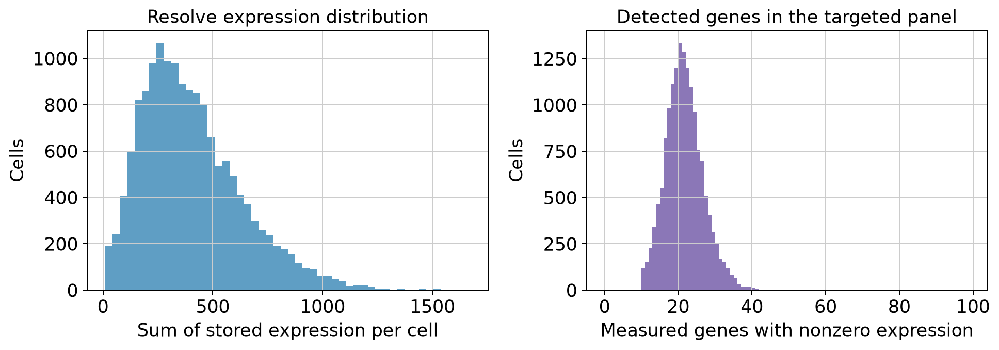

Number of cells: 15522
Number of panel genes: 98
Published sample_id categories:


sample_id
C2    5724
B2    5254
B1    4544
Name: count, dtype: int64

Published cell_type categories:


cell_type
Hep_PP_PC_2    2630
Hep_PP_PC_5    2185
Hep_PP_PC_4    1676
Hep_PP_PC_6    1476
Hep_PP_PC_3    1175
Kupffer        1134
HSC             965
LSEC_PC         736
LSEC_PP         630
Hep_PP_PC_1     467
Unk_1           457
Unk_3           413
VEC_PC          402
Unk_2           251
VEC_PP          212
T_cell          190
BEC             146
B_cell          113
Hep_Immune      105
DC               91
Fibroblast       68
Name: count, dtype: int64

In [131]:
sc.pp.calculate_qc_metrics(resolve, percent_top=None, inplace=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(resolve.obs['total_counts'], bins=50, color='#5f9ec4')
ax[0].set(xlabel='Sum of stored expression per cell', ylabel='Cells',
          title='Resolve expression distribution')
ax[1].hist(resolve.obs['n_genes_by_counts'], bins=range(0, resolve.n_vars + 2),
           color='#8b77b7')
ax[1].set(xlabel='Measured genes with nonzero expression', ylabel='Cells',
          title='Detected genes in the targeted panel')
plt.tight_layout()
plt.show()

print('Number of cells:', resolve.n_obs)
print('Number of panel genes:', resolve.n_vars)
for key in ('sample_id', 'cell_type'):
    if key in resolve.obs:
        print(f'Published {key} categories:')
        display(resolve.obs[key].value_counts().head(25))

# Keep the full published cell set by default. QC thresholds on this targeted
# panel should be selected only after inspecting the distributions.

This public Resolve file comprises 15,522 cells and 98 measured genes, distributed over three separately imaged samples: C2 (5,724 cells), B2 (5,254) and B1 (4,544). Major published classes include six Hep_PP_PC hepatocyte states as well as 1,134 Kupffer cells, 965 stellate cells, endothelial populations and rarer cell types. The histograms show QC variation within this targeted panel, not genome-wide transcriptome coverage; we retain the published cells without applying arbitrary full-transcriptome thresholds.

**Question:** The Resolve file contains only 98 measured genes. Why is it misleading to compare its detected-gene counts directly with genome-wide Visium QC thresholds?

### Step 3: Plot published cell types in tissue

The crucial advantage of imaging-based spatial transcriptomics is that expression and cell identity can be overlaid on the actual section layout. The paper includes several independent liver preparations. We therefore plot the first few samples separately; otherwise, coordinates from unrelated sections could overlap misleadingly.

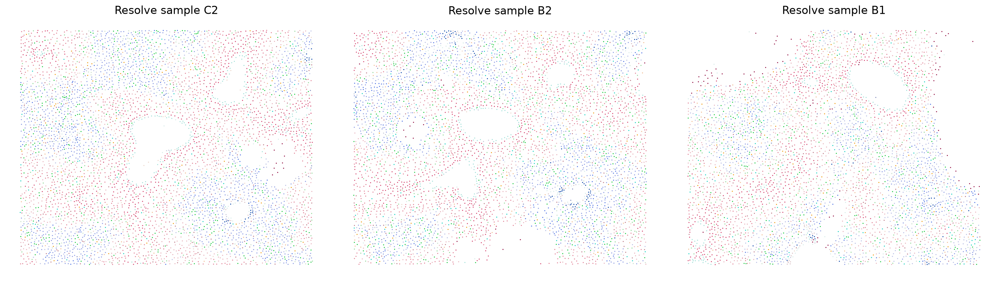

In [132]:
assert 'sample_id' in resolve.obs, 'Expected sample_id annotation is missing.'
assert 'cell_type' in resolve.obs, 'Expected cell_type annotation is missing.'

sample_names = resolve.obs['sample_id'].astype(str).value_counts().index.tolist()
sample_names = sample_names[:min(3, len(sample_names))]
fig, axes = plt.subplots(1, len(sample_names),
                         figsize=(6 * len(sample_names), 5), squeeze=False)
for ax, sample in zip(axes.ravel(), sample_names):
    mask = resolve.obs['sample_id'].astype(str) == sample
    sc.pl.embedding(resolve[mask].copy(), basis='spatial', color='cell_type',
                    ax=ax, show=False, size=7, frameon=False,
                    legend_loc=None, title=f'Resolve sample {sample}')
    ax.set_aspect('equal')
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

The three maps display C2, B2 and B1 as distinct liver sections rather than treating their coordinates as a single connected tissue. Each colored point represents one imaged cell. The maps reveal spatial organization of published hepatocyte subtypes, endothelial populations, Kupffer cells and others; distances across two different maps have no biological meaning.

### Step 4: Normalize and cluster targeted expression

The authors supply a processed `.loom` file, so we first inspect its numerical scale. If the stored values look like non-negative integer molecule counts, we normalize totals per cell and apply `log1p`. Otherwise, we retain the published scale rather than automatically transforming it again. This heuristic does not replace checking the experimental metadata.

**Safe to rerun:** `resolve.layers['published_expression']` is created only once, directly from the downloaded matrix. On every execution, `resolve.X` is first restored from that unchanged layer. This prevents repeated normalization from altering the source values or producing different clusters just because a student reran the cell.

The limited panel deliberately targets genes relevant to liver populations. Instead of highly variable gene selection designed for whole-transcriptome data, we use the measured panel directly for exploratory PCA, UMAP and Leiden clustering.

Matrix resembles molecule counts: applying total-count normalization + log1p.


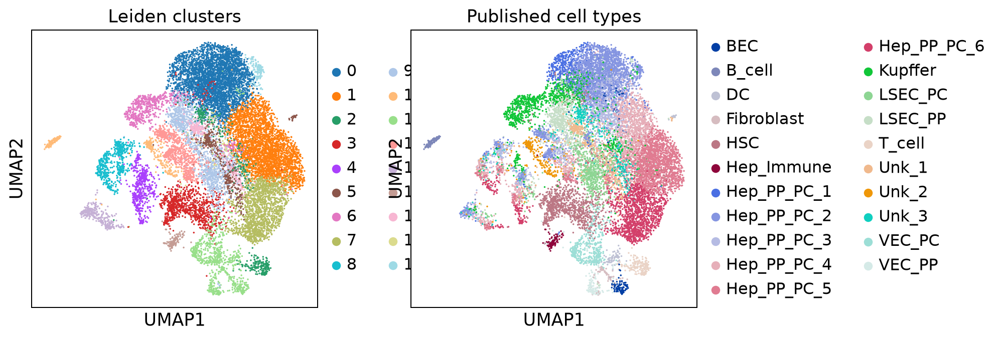

In [133]:
# Save the deposited expression values only once. Do not overwrite them
# when this normalization/clustering cell is executed repeatedly.
if 'published_expression' not in resolve.layers:
    resolve.layers['published_expression'] = resolve.X.copy()

resolve.X = resolve.layers['published_expression'].copy()
resolve.uns.pop('log1p', None)
values = np.asarray(resolve.X)
looks_like_counts = (
    np.isfinite(values).all() and values.min() >= 0 and
    np.isclose(values, np.rint(values), atol=1e-5).mean() > 0.995
)

if looks_like_counts:
    print('Matrix resembles molecule counts: applying total-count normalization + log1p.')
    sc.pp.normalize_total(resolve, target_sum=1e4)
    sc.pp.log1p(resolve)
else:
    print('Matrix does not resemble raw counts; preserving published values without re-normalizing.')
    print('Range of stored expression:', float(values.min()), float(values.max()))

resolve_scaled = resolve.copy()
sc.pp.scale(resolve_scaled, max_value=10)
n_resolve_pcs = min(30, resolve_scaled.n_obs - 1, resolve_scaled.n_vars - 1)
sc.tl.pca(resolve_scaled, n_comps=n_resolve_pcs, svd_solver='arpack')
sc.pp.neighbors(resolve_scaled, n_neighbors=15, n_pcs=min(20, n_resolve_pcs))
sc.tl.umap(resolve_scaled, random_state=42)
sc.tl.leiden(resolve_scaled, resolution=0.6,
             key_added='resolve_leiden', flavor='igraph', directed=False)

resolve.obs['resolve_leiden'] = resolve_scaled.obs['resolve_leiden'].copy()
resolve.obsm['X_umap'] = resolve_scaled.obsm['X_umap'].copy()
sc.pl.umap(resolve, color=['resolve_leiden', 'cell_type'],
           title=['Leiden clusters', 'Published cell types'])

The downloaded Resolve expression matrix passed the integer-like count check, so this run applied per-cell normalization and log1p, followed by PCA, neighbors, UMAP and Leiden clustering on the 98-gene targeted panel. The right-hand UMAP panel uses the authors' cell_type annotations, which include zonated hepatocyte labels Hep_PP_PC_1 through Hep_PP_PC_6. Visual agreement supports broad population separation, but this panel and its UMAP are not genome-wide measurements or physical tissue positions.

### Step 5: Visualize hepatocyte zonation

Carmen and colleagues report a zonation pattern organized around central and portal regions. Their results highlight Glul in pericentral hepatocytes, Cyp2e1 in pericentral/intermediate regions, and Cps1 in mid-lobular/periportal hepatocytes. Below we plot the genes actually present in the downloaded 100-gene panel and display them on one sample at a time.

We compare relative spatial patterns, not absolute numerical expression levels between technologies.

Zonation genes present in this Resolve panel: ['Glul', 'Cyp2e1', 'Cps1', 'Hal']


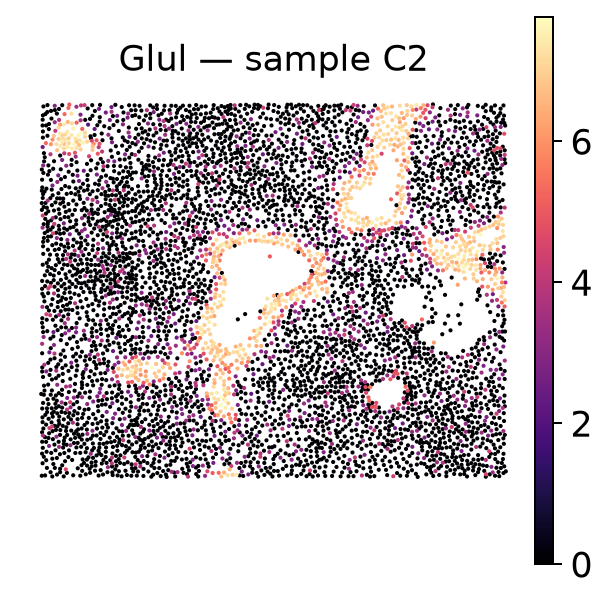

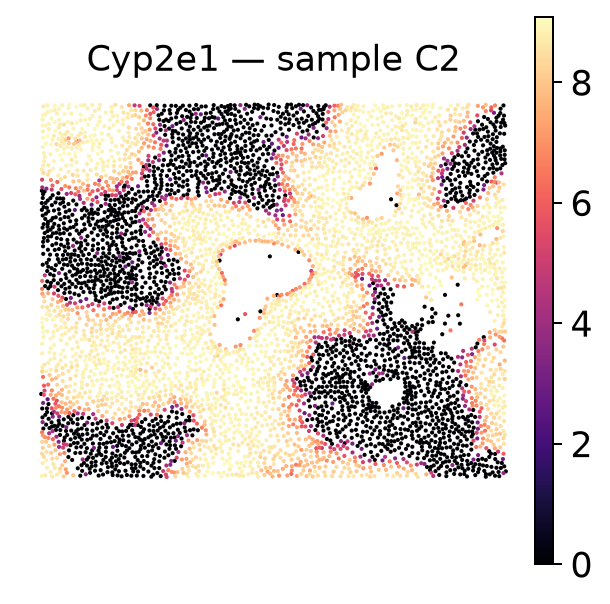

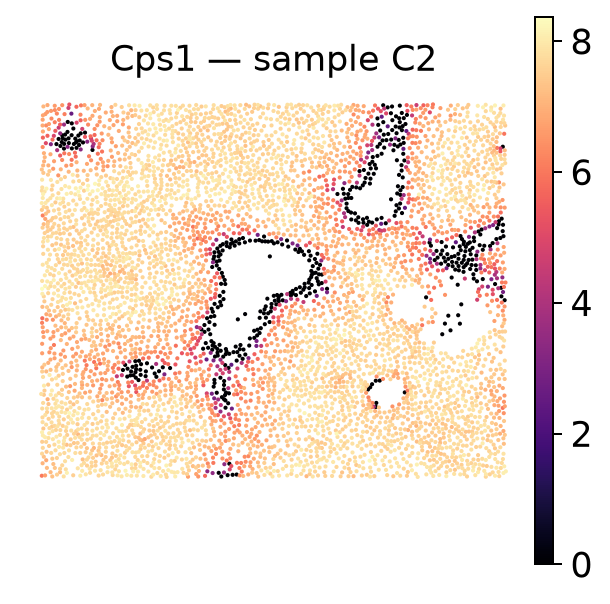

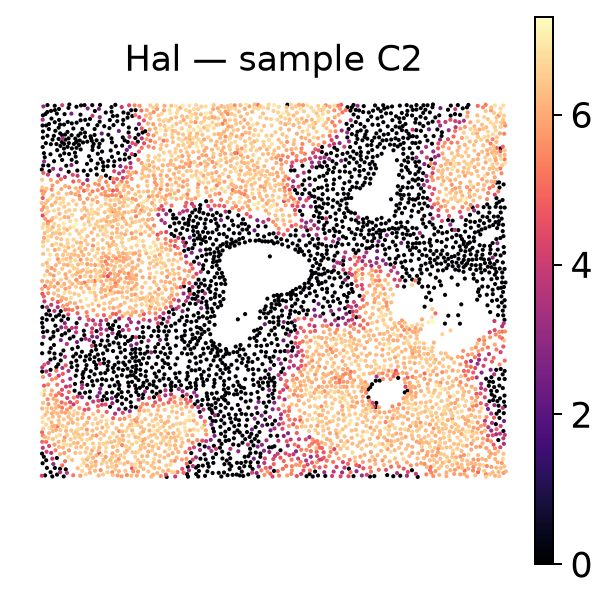

In [134]:
resolve_gene_lookup = {gene.lower(): gene for gene in resolve.var_names}
zonation_candidates = ['Glul', 'Cyp2e1', 'Cps1', 'Ass1', 'Hal', 'Pck1']
resolve_genes = [resolve_gene_lookup[g.lower()] for g in zonation_candidates
                 if g.lower() in resolve_gene_lookup]
print('Zonation genes present in this Resolve panel:', resolve_genes)
if not resolve_genes:
    print('The listed genes were not found. Inspect resolve.var_names for alternatives.')
else:
    sample_to_plot = sample_names[0]
    subset = resolve[resolve.obs['sample_id'].astype(str) == sample_to_plot].copy()
    for gene in resolve_genes[:4]:
        ax = sc.pl.embedding(subset, basis='spatial', color=gene, size=11,
                             cmap='magma', frameon=False, show=False,
                             title=f'{gene} — sample {sample_to_plot}')
        ax.set_aspect('equal')
        ax.invert_yaxis()
        plt.show()


All four plotted zonation candidates are present in the measured Resolve panel: Glul, Cyp2e1, Cps1 and Hal. The selected C2 sample lets us compare pericentral-associated expression (Glul, Cyp2e1) with other lobular programs (Cps1, Hal) using real cell positions. As with the Visium data, relative patterns do not identify a particular vessel unambiguously without tissue morphology.

### Step 6: Spatial neighborhoods in one section

A neighborhood analysis tests whether expression patterns and cell identities are spatially organized rather than distributed randomly. We construct a spatial graph using only one tissue preparation, because cells belonging to distinct samples must never be treated as neighbors.

As in the Visium and MERFISH analyses, we can inspect Moran's I for the targeted gene panel and test enrichment of particular cell-type pairings. With imaging-based data, these statistics depend on cell density, the physical scale of the graph and segmentation accuracy; they do not by themselves establish cell–cell communication.

INFO     Creating graph using `None` transform and `1` libraries.                                                  


 13%|█▎        | 13/100 [00:00<00:00, 123.94/s]

100%|██████████| 100/100 [00:00<00:00, 179.71/s]


,I,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
Cyp2e1,0.935665,0.0,0.000055,0.0,0.009901,0.000162,0.0,0.0,0.009901
Hal,0.892459,0.0,0.000055,0.0,0.009901,0.000174,0.0,0.0,0.009901
Cps1,0.863869,0.0,0.000055,0.0,0.009901,0.000138,0.0,0.0,0.009901
Glul,0.679140,0.0,0.000055,0.0,0.009901,0.000116,0.0,0.0,0.009901


100%|██████████| 100/100 [00:00<00:00, 1311.81/s]


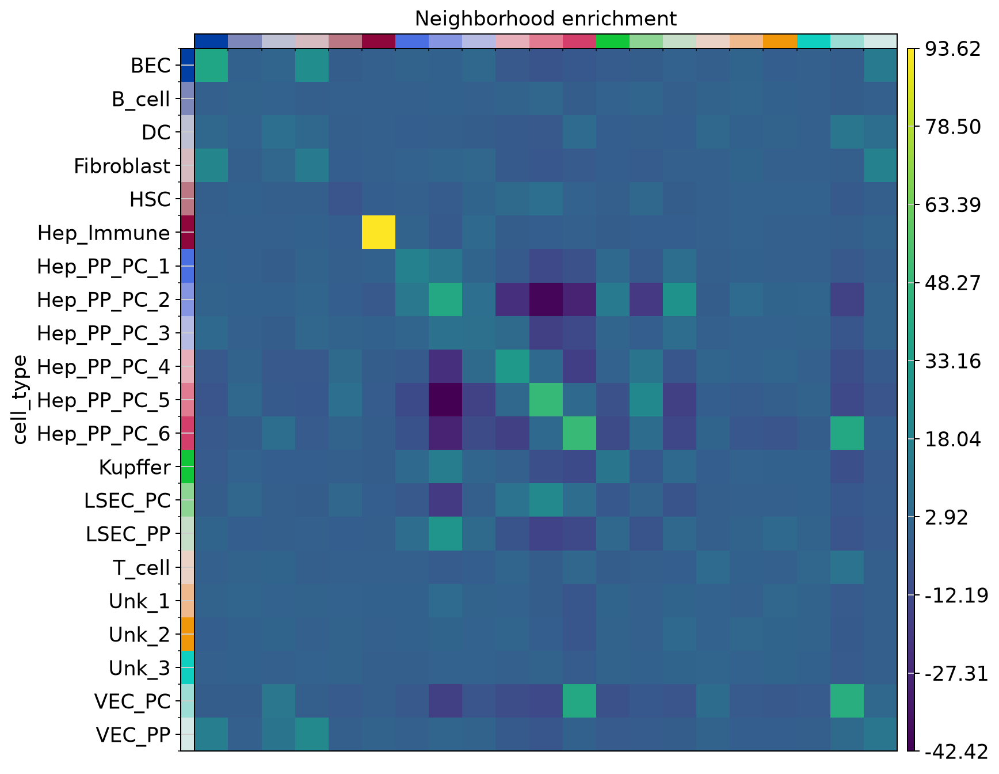

In [135]:
resolve_one_section = resolve[
    resolve.obs['sample_id'].astype(str) == sample_names[0]
].copy()
sq.gr.spatial_neighbors_knn(resolve_one_section, n_neighs=6)

sq.gr.spatial_autocorr(resolve_one_section, mode='moran',
                       genes=resolve_genes if resolve_genes else None,
                       n_perms=100, seed=42)
display(resolve_one_section.uns['moranI'].head(12))

if resolve_one_section.obs['cell_type'].nunique() > 1:
    sq.gr.nhood_enrichment(resolve_one_section, cluster_key='cell_type',
                           n_perms=100, seed=42)
    sq.pl.nhood_enrichment(resolve_one_section, cluster_key='cell_type',
                           figsize=(8, 7))

The Resolve dataset shows especially strong spatial patterning in sample C2: Cyp2e1 (Moran's I = 0.936), Hal (0.892), Cps1 (0.864) and Glul (0.679). These values exceed the corresponding Visium and MERFISH tested-gene values in this run, but they should not be directly compared as technology performance metrics, because the measurements, panels, cell/spot resolution, spatial graph and tissue sections differ. The neighbor-enrichment matrix likewise reflects the chosen six-nearest-cell graph, not proven cell-cell communication.

**Question:** Why might Moran's I differ between the Resolve and MERFISH measurements of a zonation marker, even when the gene is spatially organized in both datasets?

### Step 7: Save the processed Resolve dataset

In [136]:
RESOLVE_RESULT = RESULTS / 'resolve_mouse_liver_processed.h5ad'
resolve.write_h5ad(RESOLVE_RESULT, compression='gzip')
print('Saved processed Resolve dataset:', RESOLVE_RESULT)
print('Number of cells:', resolve.n_obs, '| Genes:', resolve.n_vars)

Saved processed Resolve dataset: /lustre1/project/stg_00002/lcb/gmoro/regulatory_genomics_course/results/spatial_liver/resolve_mouse_liver_processed.h5ad
Number of cells: 15522 | Genes: 98


## Conclusion

Three complementary technologies link gene expression to anatomical location in the liver:

1. **Visium** measures broad transcriptomes at capture spots, allowing tissue-wide expression maps and spatial domains, but a spot can contain multiple cells.
2. **MERFISH** uses a targeted gene panel and segmented cell coordinates. Its DAPI segmentation exercise demonstrates why image processing and object-level QC matter before assigning transcripts to cells.
3. **Resolve Molecular Cartography** provides an independent imaging-based view of cell identity and zonation in a targeted panel. The downloaded SCope data must be interpreted in physical spatial coordinates, not an expression UMAP.

Across all three, interpretation depends on assay resolution, preprocessing and the spatial-neighbor definition. Compare biological patterns across studies cautiously: these are different experiments and tissue sections.

## Exercises

1. **Visium QC.** Try increasing `MIN_GENES_PER_SPOT` or decreasing `MAX_MT_PERCENT`. How many spots are retained? Which tissue regions are most affected?
2. **Visium lobule.** Change `LOBULE_CENTER` and `LOBULE_HALF_WIDTH` to examine a different *interior* region. Does a vessel surrounded by *Glul*-positive spots necessarily correspond to a central vein?
3. **Watershed segmentation.** Change `MIN_SEED_DISTANCE` from 25 to 15 and inspect the number and shape of nuclear labels. Which errors increase: splitting nuclei or merging them? Compare the area filter before and after.
4. **MERFISH QC and clustering.** Repeat the workflow from Step 5 using a stricter `MERFISH_MIN_COUNTS` threshold. Does the balance of published cell types or the relationship between Leiden clusters and annotations change?
5. **MERFISH Moran's I.** Choose one zonation gene and one immune/endothelial marker. Compare their Moran's I and tissue maps. Could their different scores reflect where the corresponding cell types reside?
6. **Resolve versus MERFISH.** Pick a zonation-associated gene available in both targeted panels. Compare its spatial pattern and explain why a direct numerical comparison of Moran's I across assays is not a fair measurement of technology accuracy.

For each exercise, state what you changed, show the relevant output and interpret it in terms of the assay and liver biology.

### Further reading
- [Guilliams et al., Cell (2022)](https://doi.org/10.1016/j.cell.2021.12.018)
- [Liu et al., Life Science Alliance (2022)](https://doi.org/10.26508/lsa.202201701)
- [Annotated mouse liver MERFISH data on Figshare](https://figshare.com/articles/dataset/SingleCellData_annotated_/19310672)
- [Liu et al. analysis code](https://github.com/czbiohub-sf/MERFISH-mouse-comparison)
- [Scanpy documentation](https://scanpy.readthedocs.io/en/stable/) and [Squidpy documentation](https://squidpy.readthedocs.io/en/stable/)
